In [1]:
import os

# Verify dataset structure and count images
base_path = '/kaggle/input/deeproject/data'
healthy_path = '/kaggle/input/deeproject/data/Potato___healthy'
late_blight_path = '/kaggle/input/deeproject/data/Potato___Late_blight'  
Early_blight_path = '/kaggle/input/deeproject/data/Potato___Early_blight'

# Count images
healthy_count = len(os.listdir(healthy_path))
late_blight_count = len(os.listdir(late_blight_path))
Early_blight_count = len(os.listdir(Early_blight_path))

print(f"✅ Healthy images: {healthy_count}")
print(f"⚠️ Late Blight images: {late_blight_count}")
print(f"⚠️ Early Blight images: {Early_blight_count}")
print(f"📊 Total images: {healthy_count + late_blight_count + Early_blight_count }")
print(f"⚖️ Class imbalance ratio: {healthy_count/late_blight_count:.2f}:1")

✅ Healthy images: 666
⚠️ Late Blight images: 2067
⚠️ Early Blight images: 2000
📊 Total images: 4733
⚖️ Class imbalance ratio: 0.32:1


In [2]:
# Basic data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import cv2
from tqdm import tqdm

# Interactive visualizations - Plotly is preferred for enhanced data insights
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# TensorFlow and Keras for deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import models, layers, regularizers
# Pre-trained models for transfer learning
# 10 different architectures will be tested to identify the optimal performer
from tensorflow.keras.applications import (
    Xception, VGG16, ResNet152, InceptionV3, MobileNet,
    DenseNet121, NASNetMobile, EfficientNetV2B2, 
    ConvNeXtTiny, InceptionResNetV2
)
from tensorflow.keras.metrics import Precision, Recall
# Evaluation metrics
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    roc_curve, auc, accuracy_score, 
    precision_recall_fscore_support
)
from sklearn.model_selection import train_test_split

# Configuration
warnings.filterwarnings('ignore')
sns.set_palette("husl")

print("✅ All libraries imported successfully")
print(f"TensorFlow version: {tf.__version__}")

2026-01-16 04:56:44.521120: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1768539404.710100      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1768539404.764175      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1768539405.222573      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768539405.222621      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1768539405.222624      23 computation_placer.cc:177] computation placer alr

✅ All libraries imported successfully
TensorFlow version: 2.19.0


In [3]:
# Define dataset paths
healthy_path = '/kaggle/input/deeproject/data/Potato___healthy'
late_blight_path = '/kaggle/input/deeproject/data/Potato___Late_blight'  
Early_blight_path = '/kaggle/input/deeproject/data/Potato___Early_blight'

# Class names for labeling
class_names = ['Healthy', 'Late Blight' , 'Early Blight']

print("Loading dataset...")
print("=" * 60)

# Initialize lists for paths and labels
image_paths = []
labels = []

# Load Healthy images (label = 0)
healthy_files = [f for f in os.listdir(healthy_path) 
                 if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
for filename in healthy_files:
    image_paths.append(os.path.join(healthy_path, filename))
    labels.append(0)

# Load Late Blight images (label = 1)
late_blight_files = [f for f in os.listdir(late_blight_path) 
                     if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
for filename in late_blight_files:
    image_paths.append(os.path.join(late_blight_path, filename))
    labels.append(1)

Early_blight_files = [f for f in os.listdir(Early_blight_path) 
                     if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
for filename in Early_blight_files:
    image_paths.append(os.path.join(Early_blight_path, filename))
    labels.append(2)

# Convert to numpy arrays
image_paths = np.array(image_paths)
labels = np.array(labels)

# Summary statistics
print(f"✅ Dataset loaded successfully")
print(f"   Total images: {len(image_paths)}")
print(f"   • Healthy: {len(healthy_files)} images")
print(f"   • Late Blight: {len(late_blight_files)} images")
print(f"   • Early Blight: {len(Early_blight_files)} images")
print(f"   • Class ratio: {len(healthy_files)/len(late_blight_files):.2f}:1")
print("=" * 60)

Loading dataset...
✅ Dataset loaded successfully
   Total images: 4733
   • Healthy: 666 images
   • Late Blight: 2067 images
   • Early Blight: 2000 images
   • Class ratio: 0.32:1


In [4]:
import os
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# --- 🛠️ FIX FOR PLOTS NOT SHOWING ---
# In Kaggle/Jupyter, this tells Plotly how to display the JS.
# If 'iframe' doesn't work, try changing it to 'notebook' or 'colab'
pio.renderers.default = 'iframe'  

# ==========================================
# 1. SETUP PATHS & DATA
# ==========================================
# Define dataset paths
base_dir = '/kaggle/input/deeproject/data'

# Dictionary mapping Class Names -> Folder Paths
paths = {
    'Healthy': os.path.join(base_dir, 'Potato___healthy'),
    'Late Blight': os.path.join(base_dir, 'Potato___Late_blight'),
    'Early Blight': os.path.join(base_dir, 'Potato___Early_blight')
}

# Mapping labels to integers
label_map = { 'Healthy': 0, 'Late Blight': 1, 'Early Blight': 2 }

print("Loading dataset...")
print("=" * 60)

image_paths = []
labels = []
class_counts = {}

# ==========================================
# 2. LOAD IMAGES
# ==========================================
for class_name, folder_path in paths.items():
    if os.path.exists(folder_path):
        # Filter for images only
        valid_files = [f for f in os.listdir(folder_path) 
                       if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        
        # Add to lists
        for filename in valid_files:
            image_paths.append(os.path.join(folder_path, filename))
            labels.append(label_map[class_name])
            
        class_counts[class_name] = len(valid_files)
        print(f"✅ Loaded {class_name}: {len(valid_files)} images")
    else:
        print(f"❌ Error: Path not found for {class_name}")
        class_counts[class_name] = 0

# Convert to Numpy
image_paths = np.array(image_paths)
labels = np.array(labels)
class_names = list(paths.keys()) # ['Healthy', 'Late Blight', 'Early Blight']

# ==========================================
# 3. VISUALIZATION (Plotly)
# ==========================================
unique, counts = np.unique(labels, return_counts=True)

# Colors: Green for Healthy, Red for Late Blight, Orange for Early Blight
color_palette = ['#2ecc71', '#e74c3c', '#f39c12']

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Class Distribution (Count)', 'Proportion Analysis (%)'),
    specs=[[{"type": "bar"}, {"type": "pie"}]]
)

# Bar Chart
fig.add_trace(
    go.Bar(
        x=[class_names[i] for i in unique], 
        y=counts,
        marker_color=color_palette,
        text=counts,
        textposition='auto',
        name="Count"
    ),
    row=1, col=1
)

# Pie Chart
fig.add_trace(
    go.Pie(
        labels=[class_names[i] for i in unique],
        values=counts,
        marker_colors=color_palette,
        hole=0.4, # Donut style
        textinfo='label+percent',
        name="Percentage"
    ),
    row=1, col=2
)

fig.update_layout(
    title_text="🥔 Potato Disease Dataset Distribution",
    title_font_size=20,
    showlegend=True,
    height=500,
    template="plotly_white"
)

# Display the chart
fig.show()

# ==========================================
# 4. STATISTICS & EXPERT ASSESSMENT
# ==========================================
print("\n📊 Detailed Statistics:")
print("=" * 60)

total_images = len(image_paths)

for i, idx in enumerate(unique):
    name = class_names[idx]
    count = counts[i]
    percentage = (count / total_images) * 100
    print(f"{name:15s}: {count:4d} images ({percentage:.2f}%)")

print("=" * 60)

# Imbalance Calculation
if len(counts) > 0:
    imbalance_ratio = max(counts) / min(counts)
    print(f"⚖️  Imbalance Ratio: {imbalance_ratio:.2f}:1")

    # Expert Assessment Logic
    if imbalance_ratio > 5:
        print("\n⚠️  Significant class imbalance detected (>5:1)")
        print("   Action Plan:")
        print("   1. Use Class Weights (sklearn.utils.class_weight)")
        print("   2. Augment the minority class (Rotation/Flip)")
    elif imbalance_ratio > 2:
        print("\n⚡ Moderate imbalance (2-5:1)")
        print("   Action Plan: Monitor Validation F1-Score closely.")
    else:
        print("\n✅ Dataset is relatively balanced. Standard training should work.")
else:
    print("❌ No data found.")

Loading dataset...
✅ Loaded Healthy: 666 images
✅ Loaded Late Blight: 2067 images
✅ Loaded Early Blight: 2000 images



📊 Detailed Statistics:
Healthy        :  666 images (14.07%)
Late Blight    : 2067 images (43.67%)
Early Blight   : 2000 images (42.26%)
⚖️  Imbalance Ratio: 3.10:1

⚡ Moderate imbalance (2-5:1)
   Action Plan: Monitor Validation F1-Score closely.



📸 SAMPLE IMAGES FROM DATASET
   Visual inspection for quality assurance and pattern recognition



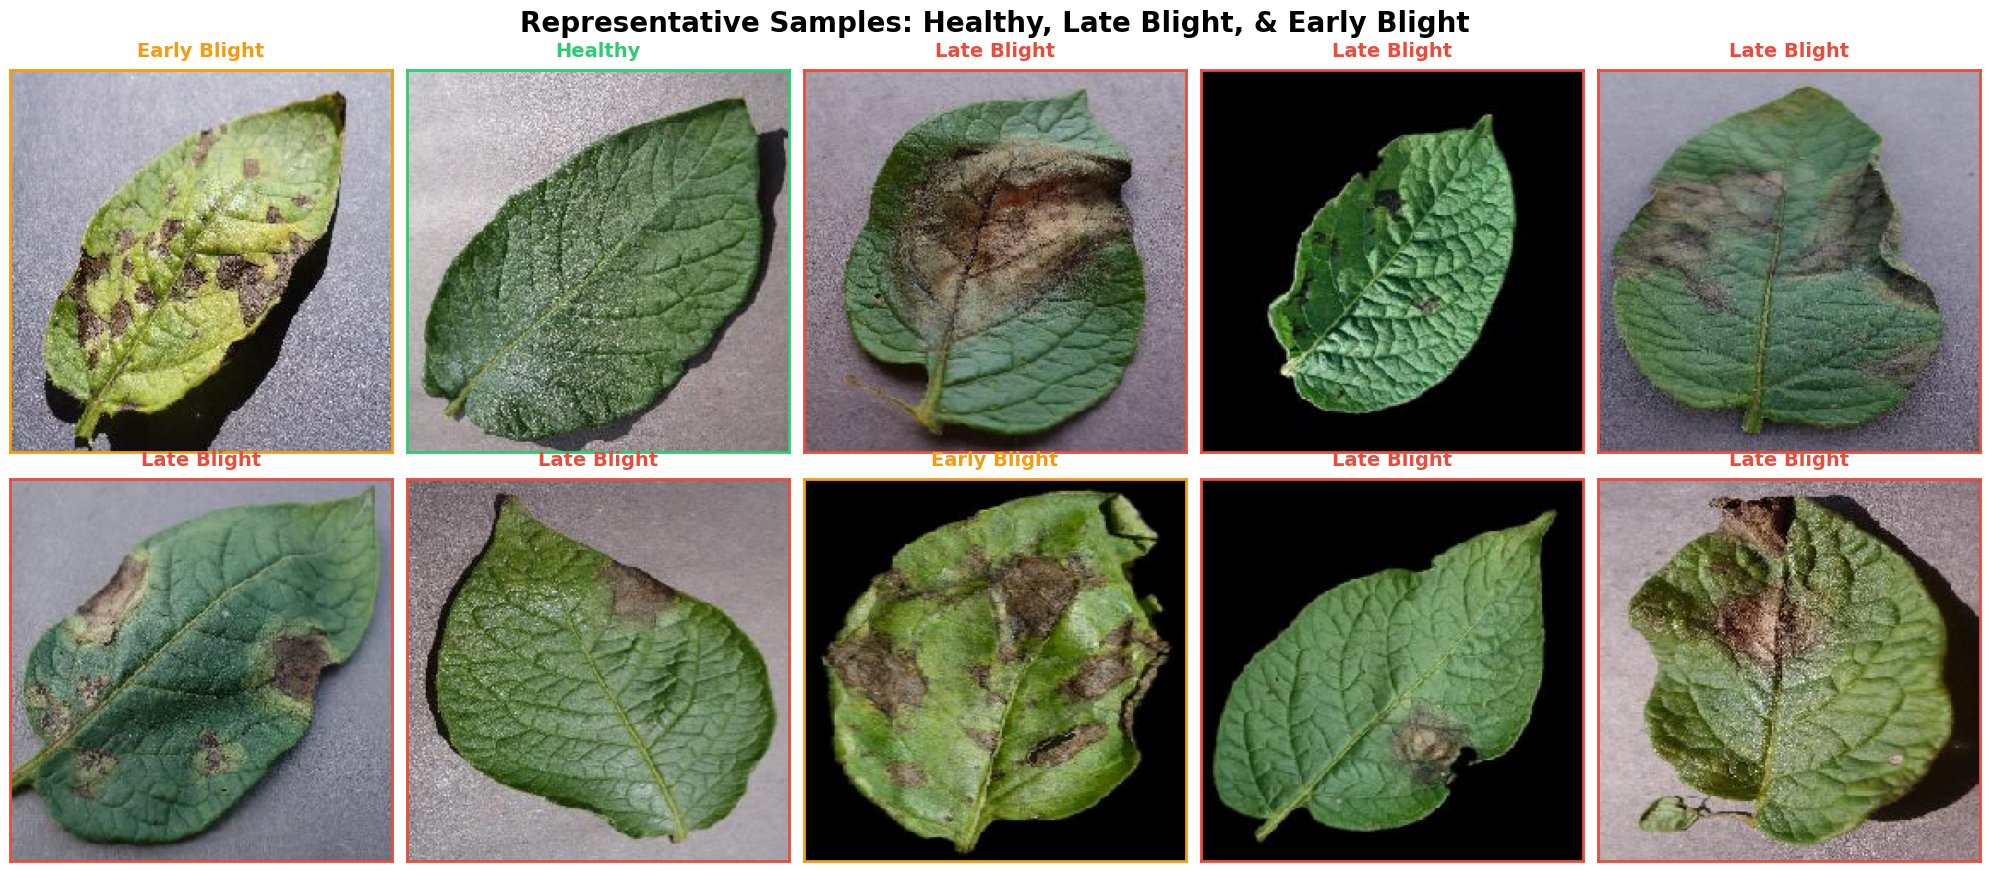


✅ Visual inspection complete
   Key observations:
   • Image quality: Sufficient resolution (224x224) for feature extraction
   • Class Indicators:
     - 🟢 Healthy: Intact leaves, uniform texture
     - 🔴 Late Blight: Large dark/black lesions, watery rot looks
     - 🟠 Early Blight: Concentric rings (bullseye pattern), brown spots
   • Background variability: Mix of field conditions


In [5]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img

# Display sample images from all classes
print("\n" + "=" * 80)
print("📸 SAMPLE IMAGES FROM DATASET")
print("   Visual inspection for quality assurance and pattern recognition")
print("=" * 80 + "\n")

# Setup figure
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
fig.suptitle('Representative Samples: Healthy, Late Blight, & Early Blight', 
             fontsize=20, fontweight='bold', y=0.98)

# Select 10 random samples from the dataset
indices = np.random.choice(len(image_paths), 10, replace=False)

# Define colors for specific labels
# 0: Healthy (Green), 1: Late Blight (Red), 2: Early Blight (Orange)
label_colors = {0: '#2ecc71', 1: '#e74c3c', 2: '#f39c12'}

for idx, ax in enumerate(axes.flat):
    # Load image
    img_path = image_paths[indices[idx]]
    img = load_img(img_path, target_size=(224, 224))
    
    # Display image
    ax.imshow(img)
    
    # Get Label info
    label_idx = labels[indices[idx]]
    current_class = class_names[label_idx]
    current_color = label_colors.get(label_idx, 'black') # Default to black if error
    
    # Set Title with specific color
    ax.set_title(current_class, 
                 fontsize=14, fontweight='bold', 
                 color=current_color, pad=10)
    
    # Add border to image matching the class color
    for spine in ax.spines.values():
        spine.set_edgecolor(current_color)
        spine.set_linewidth(2)
        
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

print("\n✅ Visual inspection complete")
print("   Key observations:")
print("   • Image quality: Sufficient resolution (224x224) for feature extraction")
print("   • Class Indicators:")
print(f"     - 🟢 Healthy: Intact leaves, uniform texture")
print(f"     - 🔴 Late Blight: Large dark/black lesions, watery rot looks")
print(f"     - 🟠 Early Blight: Concentric rings (bullseye pattern), brown spots")
print("   • Background variability: Mix of field conditions")

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from tensorflow.keras.preprocessing.image import load_img

# Define standard palette for consistency
# 0: Healthy, 1: Late Blight, 2: Early Blight
COLORS = ['#2ecc71', '#e74c3c', '#f39c12']  # Green, Red, Orange

def plot_sample_images(image_paths, labels, class_names, n_samples=10, figsize=(20, 8)):
    """
    Displays a grid of random sample images with class-colored labels.
    """
    fig, axes = plt.subplots(2, 5, figsize=figsize)
    fig.suptitle('Sample Images from Dataset', fontsize=20, fontweight='bold', y=0.98)
    
    indices = np.random.choice(len(image_paths), n_samples, replace=False)
    
    for idx, ax in enumerate(axes.flat):
        img_path = image_paths[indices[idx]]
        label_idx = labels[indices[idx]]
        
        img = load_img(img_path, target_size=(224, 224))
        ax.imshow(img)
        
        # Color-code titles based on class index
        # Green for Healthy, Red/Orange for Blights
        title_color = COLORS[label_idx] if label_idx < len(COLORS) else 'black'
        
        ax.set_title(class_names[label_idx], 
                     fontsize=13, fontweight='bold', color=title_color, pad=8)
        
        # Add a colored border
        for spine in ax.spines.values():
            spine.set_edgecolor(title_color)
            spine.set_linewidth(2)
            
        ax.set_xticks([])
        ax.set_yticks([])
    
    plt.tight_layout()
    plt.show()


def plot_class_distribution(labels, class_names):
    """
    Creates interactive bar and pie charts showing class distribution for 3 classes.
    """
    unique, counts = np.unique(labels, return_counts=True)
    
    fig = make_subplots(
        rows=1, cols=2,
        subplot_titles=('Class Distribution', 'Proportion View'),
        specs=[[{"type": "bar"}, {"type": "pie"}]]
    )
    
    # Bar chart
    fig.add_trace(
        go.Bar(
            x=[class_names[i] for i in unique], 
            y=counts,
            marker_color=COLORS,
            text=counts,
            textposition='auto',
            name="Count"
        ),
        row=1, col=1
    )
    
    # Donut chart
    fig.add_trace(
        go.Pie(
            labels=[class_names[i] for i in unique],
            values=counts,
            marker_colors=COLORS,
            hole=0.4,
            textinfo='label+percent',
            name="Percent"
        ),
        row=1, col=2
    )
    
    fig.update_layout(
        title_text="Dataset Class Distribution Analysis",
        title_font_size=18,
        showlegend=True,
        height=450,
        template='plotly_white'
    )
    
    fig.show()
    
    # Quantitative summary
    print("\nClass Distribution Statistics:")
    print("=" * 60)
    for i, name in enumerate(class_names):
        percentage = (counts[i] / len(labels)) * 100
        print(f"{name:15s}: {counts[i]:4d} images ({percentage:.2f}%)")
    print("=" * 60)
    
    # Automated assessment
    ratio = max(counts) / min(counts)
    print(f"⚖️ Imbalance Ratio: {ratio:.2f}:1")
    
    if ratio > 5:
        print("⚠️ Significant imbalance detected. Suggest using Class Weights.")
    elif ratio > 2:
        print("⚡ Moderate imbalance. Ensure Stratified Splitting.")
    else:
        print("✅ Dataset is relatively balanced.")


def plot_training_history(history, model_name, figsize=(15, 6)):
    """
    Visualizes training and validation metrics across epochs.
    """
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    
    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Training', linewidth=2, color='#3498db')
    axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2, color='#e74c3c')
    axes[0].set_title(f'{model_name} - Accuracy', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend(loc='lower right')
    axes[0].grid(True, alpha=0.3)
    
    # Loss
    axes[1].plot(history.history['loss'], label='Training', linewidth=2, color='#3498db')
    axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2, color='#e74c3c')
    axes[1].set_title(f'{model_name} - Loss', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_true, y_pred, class_names, model_name):
    """
    Generates confusion matrix for Multi-Class (3 classes).
    """
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={'size': 14, 'weight': 'bold'})
    
    plt.title(f'{model_name} - Confusion Matrix', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('True Label', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Class-wise accuracy
    print("\n📊 Per-Class Accuracy Analysis:")
    print("=" * 40)
    # Diagonal elements are correct predictions
    for i, name in enumerate(class_names):
        total_samples = np.sum(cm[i, :]) # Sum of row
        correct = cm[i, i]
        acc = correct / total_samples if total_samples > 0 else 0
        print(f"{name:15s}: {acc:.2%} correct ({correct}/{total_samples})")


def plot_roc_curve(y_true, y_pred_proba, class_names, model_name):
    """
    Plots ROC curve using One-vs-Rest strategy for Multi-Class data.
    """
    n_classes = len(class_names)
    
    # Binarize the output (One-hot encoding for true labels)
    y_true_bin = label_binarize(y_true, classes=range(n_classes))
    
    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    
    plt.figure(figsize=(10, 7))
    
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_proba[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        
        plt.plot(fpr[i], tpr[i], lw=2.5,
                 label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2, alpha=0.7)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(f'{model_name} - Multi-Class ROC Curve', fontsize=16, fontweight='bold')
    plt.legend(loc="lower right", fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("✅ Visualization framework updated for 3-Class System")
print("   • Colors configured: Green (Healthy), Red (Late), Orange (Early)")
print("   • ROC Curve updated to One-vs-Rest")
print("   • Confusion Matrix updated for multi-class analysis")

✅ Visualization framework updated for 3-Class System
   • Colors configured: Green (Healthy), Red (Late), Orange (Early)
   • ROC Curve updated to One-vs-Rest
   • Confusion Matrix updated for multi-class analysis


In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# ==========================================
# 1. CREATE DATAFRAME
# ==========================================
# We use a DataFrame because it works best with Keras "flow_from_dataframe"
# and makes inspecting the data much easier.
df = pd.DataFrame({
    'filepath': image_paths,
    'label_code': labels,
    'class_name': [class_names[l] for l in labels] # Maps 0->Healthy, 1->Late, etc.
})

print("✅ DataFrame created successfully")
print(f"   Total Samples: {len(df)}")

# ==========================================
# 2. STRATIFIED SPLIT (Train / Val / Test)
# ==========================================
print("\n🔄 Splitting Data (80% Train, 10% Val, 10% Test)...")

# 1. Split Train (80%) and Temp (20%)
train_df, temp_df = train_test_split(
    df, 
    train_size=0.8, 
    shuffle=True, 
    random_state=42, 
    stratify=df['class_name'] # Ensures 3 classes are balanced
)

# 2. Split Temp into Validation (50% of 20% = 10%) and Test (remaining 10%)
val_df, test_df = train_test_split(
    temp_df, 
    train_size=0.5, 
    shuffle=True, 
    random_state=42, 
    stratify=temp_df['class_name']
)

# Reset indices for cleanliness
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("=" * 60)
print(f"📊 Split Results:")
print(f"   • Training Set:   {len(train_df)} images")
print(f"   • Validation Set: {len(val_df)} images")
print(f"   • Test Set:       {len(test_df)} images")
print("=" * 60)

# Check Stratification (Verify percentages match)
def check_stratification(data, name):
    counts = data['class_name'].value_counts(normalize=True) * 100
    print(f"\n{name} Distribution:")
    print(counts.to_string(float_format="%.2f%%"))

check_stratification(train_df, "Training")
check_stratification(val_df, "Validation")

# ==========================================
# 3. DATA GENERATORS (Augmentation)
# ==========================================
# Configuration
BATCH_SIZE = 32
IMG_SIZE = (224, 224) # Standard for most pre-trained models (VGG, ResNet)

print("\n⚙️ Configuring Image Generators...")

# A. Training Generator (WITH Augmentation)
# This creates new variations of images on the fly to prevent overfitting
train_datagen = ImageDataGenerator(
    rescale=1./255,             # Normalize pixel values 0-1
    rotation_range=20,          # Rotate slightly
    width_shift_range=0.1,      # Shift left/right
    height_shift_range=0.1,     # Shift up/down
    shear_range=0.1,            # Slant
    zoom_range=0.1,             # Zoom in/out
    horizontal_flip=True,       # Mirror image
    fill_mode='nearest'
)

# B. Test/Val Generator (NO Augmentation)
# Validation data must remain "real" to accurately check performance
test_datagen = ImageDataGenerator(rescale=1./255)

# C. Create Flows
print("   • initializing train_gen...")
train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print("   • initializing val_gen...")
val_gen = test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # False helps with stability in evaluation
)

print("   • initializing test_gen...")
test_gen = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("\n✅ Data Pipeline Ready!")
print(f"   Class Mapping: {train_gen.class_indices}")

✅ DataFrame created successfully
   Total Samples: 4733

🔄 Splitting Data (80% Train, 10% Val, 10% Test)...
📊 Split Results:
   • Training Set:   3786 images
   • Validation Set: 473 images
   • Test Set:       474 images

Training Distribution:
class_name
Late Blight    43.66%
Early Blight   42.26%
Healthy        14.08%

Validation Distribution:
class_name
Late Blight    43.76%
Early Blight   42.28%
Healthy        13.95%

⚙️ Configuring Image Generators...
   • initializing train_gen...
Found 3786 validated image filenames belonging to 3 classes.
   • initializing val_gen...
Found 473 validated image filenames belonging to 3 classes.
   • initializing test_gen...
Found 474 validated image filenames belonging to 3 classes.

✅ Data Pipeline Ready!
   Class Mapping: {'Early Blight': 0, 'Healthy': 1, 'Late Blight': 2}


In [8]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# ==========================================
# 1. CALCULATE CLASS WEIGHTS (Automated)
# ==========================================
# We use the 'train_df' created in the previous splitting step
y_train_labels = train_df['label_code'].values
unique_classes = np.unique(y_train_labels)

# Automatically compute balanced weights for 3 classes
weights = compute_class_weight(
    class_weight='balanced', 
    classes=unique_classes, 
    y=y_train_labels
)

# Convert to dictionary format required by Keras {0: 1.0, 1: 2.5, ...}
class_weights = dict(zip(unique_classes, weights))

print("⚖️  Class Weight Configuration:")
print("=" * 70)
for idx, weight in class_weights.items():
    class_name = class_names[idx]
    print(f"   • {class_name:15s} (Label {idx}): Weight {weight:.3f}")

# Calculate ratio comparison for insight
min_weight = min(weights)
max_weight = max(weights)
print("-" * 70)
print(f"   Effect: Minority class samples count {max_weight/min_weight:.2f}x more than majority class.")
print("=" * 70)


# ==========================================
# 2. IMAGE GENERATORS (Aggressive Augmentation)
# ==========================================
print("\n⚙️  Configuring Data Pipelines...")

# Training: Aggressive Augmentation (As requested)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,          # High rotation
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,         # Added vertical flip (useful for top-down leaf photos)
    brightness_range=[0.7, 1.3],# Vary lighting
    fill_mode='nearest'
)

# Validation: Rescale Only (No augmentation)
val_datagen = ImageDataGenerator(rescale=1./255)

# ==========================================
# 3. CREATE DATA FLOWS
# ==========================================
# Using flow_from_dataframe is faster and more stable than custom Python loops

print("   • Creating Training Stream...")
train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
val_gen = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False 
)

# Steps calculation
train_steps = train_gen.samples // BATCH_SIZE
val_steps = val_gen.samples // BATCH_SIZE

print("\n✅ Data preparation complete")
print(f"   Training steps per epoch: {train_steps}")
print(f"   Validation steps: {val_steps}")
print(f"   Batch size: {BATCH_SIZE}")

⚖️  Class Weight Configuration:
   • Healthy         (Label 0): Weight 2.368
   • Late Blight     (Label 1): Weight 0.763
   • Early Blight    (Label 2): Weight 0.789
----------------------------------------------------------------------
   Effect: Minority class samples count 3.10x more than majority class.

⚙️  Configuring Data Pipelines...
   • Creating Training Stream...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 473 validated image filenames belonging to 3 classes.

✅ Data preparation complete
   Training steps per epoch: 118
   Validation steps: 14
   Batch size: 32



🎨 AUGMENTATION PREVIEW
   Demonstrating transformations on a real 'Late Blight' sample



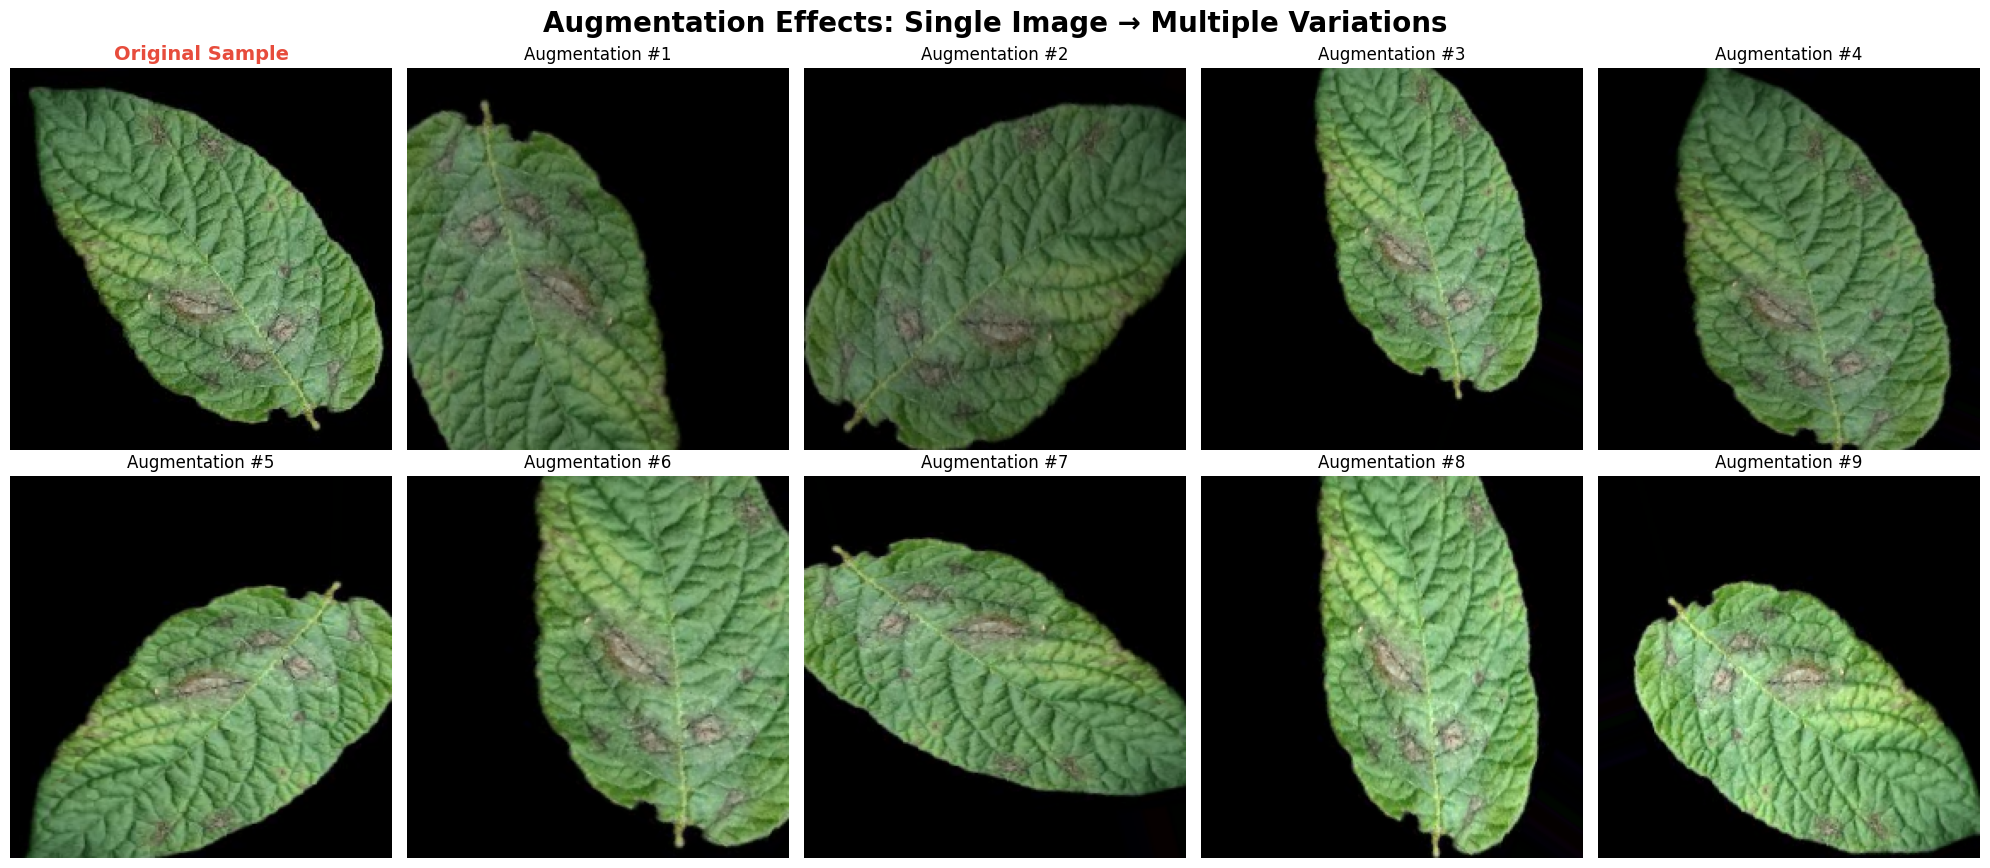


📊 Augmentation Impact Analysis:
   • Training Set Size: 3786
   • Theoretical Expansion: Infinite
   • Why this matters: The model never sees the exact same image twice.
   • Benefit: Forces the model to learn features (lesion shape) rather than memorizing pixels.


In [9]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# ==========================================
# VISUALIZE DATA AUGMENTATION
# ==========================================
print("\n" + "=" * 80)
print("🎨 AUGMENTATION PREVIEW")
print("   Demonstrating transformations on a real 'Late Blight' sample")
print("=" * 80 + "\n")

# 1. Select a random "Late Blight" image from the Training DataFrame
# Using the DataFrame ensures we pick from the actual training set
late_blight_samples = train_df[train_df['class_name'] == 'Late Blight']

if not late_blight_samples.empty:
    # Pick the first one or a random one
    sample_row = late_blight_samples.iloc[0] 
    sample_path = sample_row['filepath']
    
    # 2. Load and Convert Image
    # Load at the target size defined earlier (224x224)
    original_img = load_img(sample_path, target_size=IMG_SIZE)
    img_array = img_to_array(original_img) # Range 0-255
    
    # 3. Create Visualization Grid
    fig, axes = plt.subplots(2, 5, figsize=(20, 9))
    fig.suptitle('Augmentation Effects: Single Image → Multiple Variations', 
                 fontsize=20, fontweight='bold', y=0.98)

    # Plot Original (Top Left)
    axes[0, 0].imshow(img_array.astype('uint8'))
    axes[0, 0].set_title('Original Sample', fontsize=14, fontweight='bold', color='#e74c3c')
    axes[0, 0].axis('off')
    
    # Add a red border to original
    for spine in axes[0,0].spines.values():
        spine.set_edgecolor('#e74c3c')
        spine.set_linewidth(3)

    # Generate 9 augmented versions
    # We iterate through the grid, skipping the first spot (0,0)
    for i in range(1, 10):
        # Apply transformation
        # Note: random_transform applies spatial/color shifts but NOT the rescale (1/255)
        # We pass .copy() so we don't modify the original array in memory
        aug_img = train_datagen.random_transform(img_array.copy())
        
        # Calculate grid position
        row = i // 5
        col = i % 5
        
        # Display
        # cast to uint8 (0-255) for valid matplotlib display
        axes[row, col].imshow(aug_img.astype('uint8'))
        axes[row, col].set_title(f'Augmentation #{i}', fontsize=12)
        axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()

    # 4. Statistical Context
    print("\n📊 Augmentation Impact Analysis:")
    print(f"   • Training Set Size: {len(train_df)}")
    print(f"   • Theoretical Expansion: Infinite")
    print(f"   • Why this matters: The model never sees the exact same image twice.")
    print(f"   • Benefit: Forces the model to learn features (lesion shape) rather than memorizing pixels.")

else:
    print("❌ Error: No Late Blight images found in the training dataframe.")


📸 AUGMENTED TRAINING SAMPLES: All Classes
   Visualizing how the model sees the data after random transformations



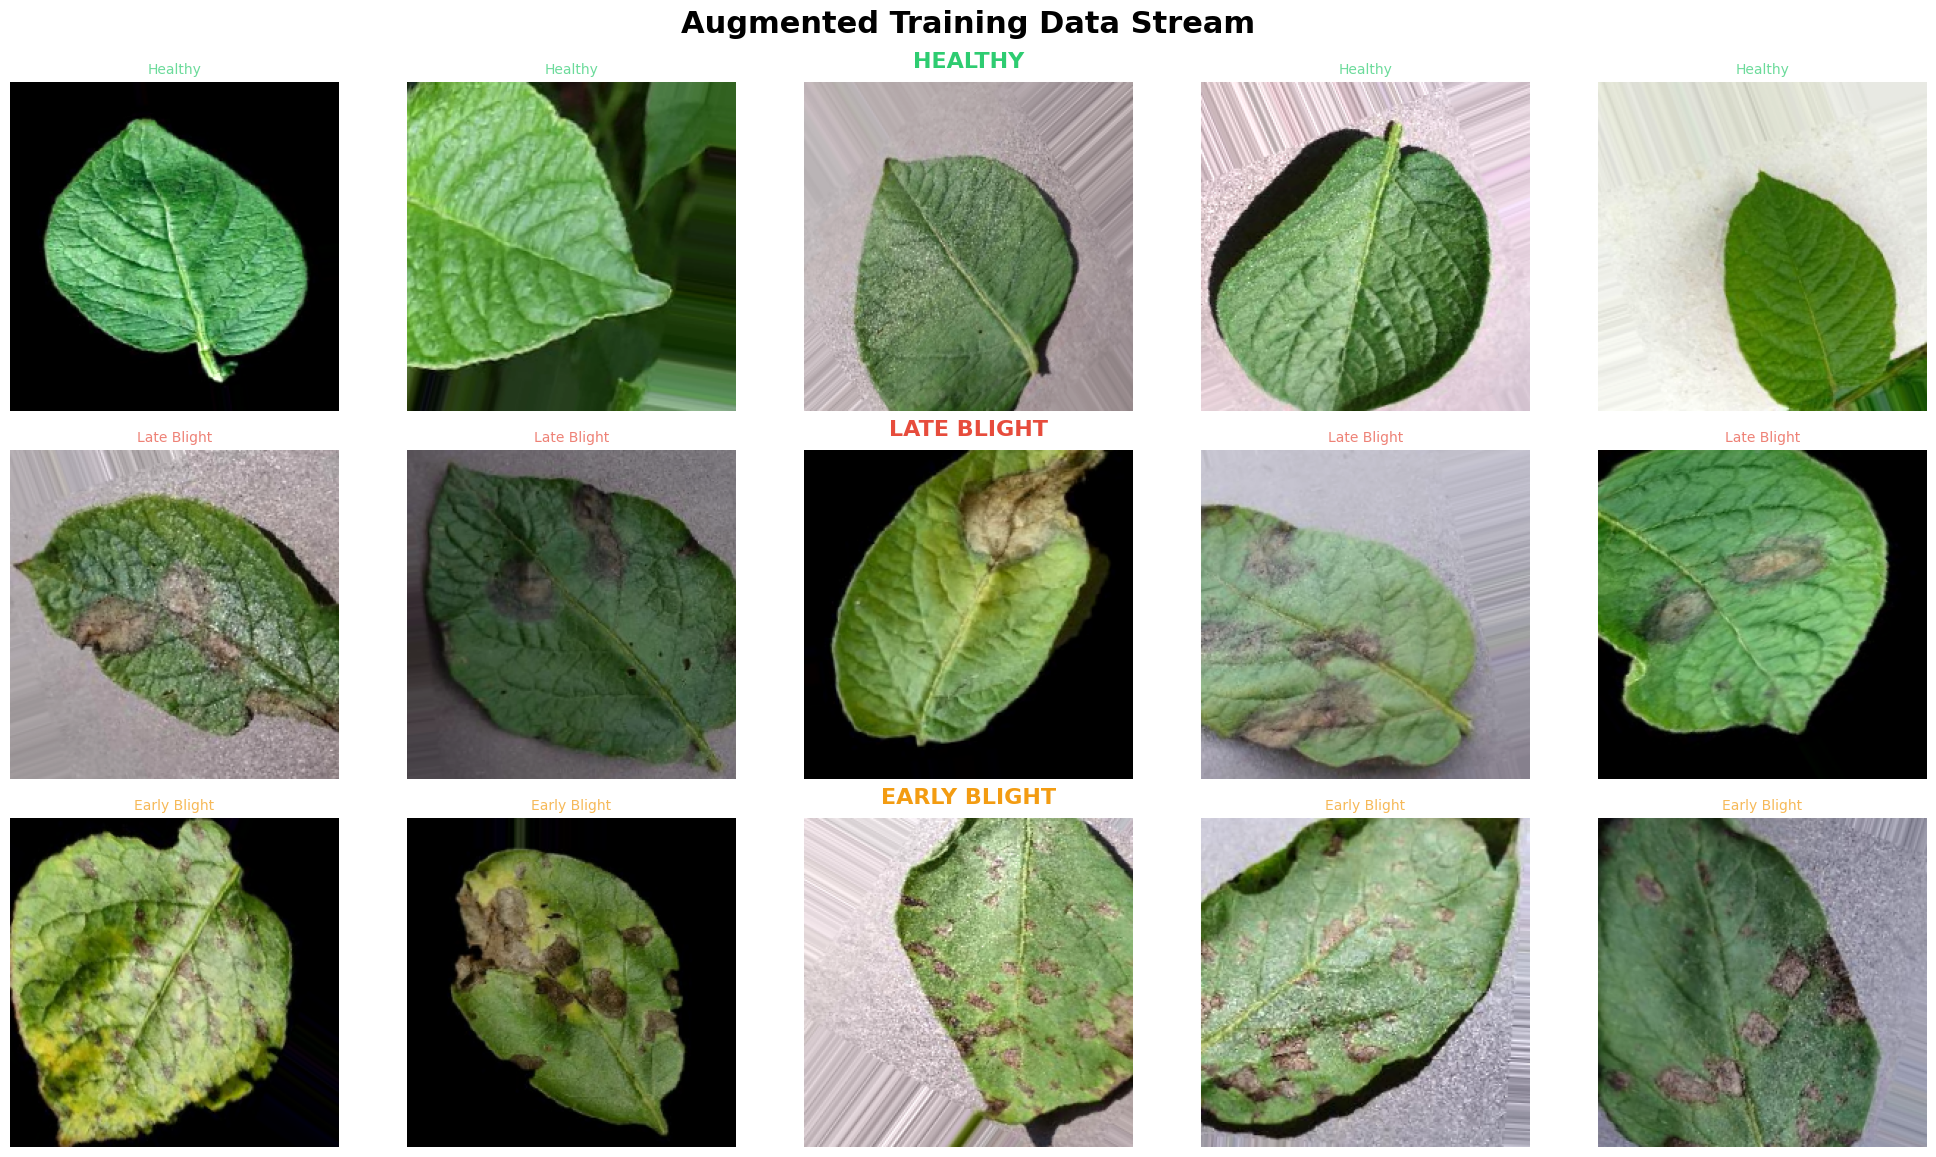


✅ Augmentation Check Complete
   Observations:
   • Orientations are varied (Rotation working)
   • Lighting conditions vary (Brightness working)
   • No black artifacts at edges (Fill mode 'nearest' working)


In [10]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# ==========================================
# VISUALIZE AUGMENTED SAMPLES (All 3 Classes)
# ==========================================
print("\n" + "=" * 80)
print("📸 AUGMENTED TRAINING SAMPLES: All Classes")
print("   Visualizing how the model sees the data after random transformations")
print("=" * 80 + "\n")

# Define Classes and specific colors
# You can easily add more classes here if the dataset grows
targets = [
    {'name': 'Healthy',      'color': '#2ecc71'}, # Green
    {'name': 'Late Blight',  'color': '#e74c3c'}, # Red
    {'name': 'Early Blight', 'color': '#f39c12'}  # Orange
]

# Create a grid: 3 Rows (Classes) x 5 Columns (Samples)
fig, axes = plt.subplots(len(targets), 5, figsize=(20, 12))
fig.suptitle('Augmented Training Data Stream', fontsize=22, fontweight='bold', y=0.96)

for row_idx, target in enumerate(targets):
    class_name = target['name']
    color = target['color']
    
    # 1. Get 5 random samples for this specific class from the Training DataFrame
    class_samples = train_df[train_df['class_name'] == class_name].sample(5, replace=False)
    
    for col_idx, (_, row_data) in enumerate(class_samples.iterrows()):
        ax = axes[row_idx, col_idx]
        
        # 2. Load Image
        img_path = row_data['filepath']
        img = load_img(img_path, target_size=IMG_SIZE)
        img_array = img_to_array(img)
        
        # 3. Apply Random Augmentation
        # This applies the rotation, zoom, brightness defined in train_datagen
        aug_img = train_datagen.random_transform(img_array)
        
        # 4. Display (Normalize to 0-1 for Matplotlib)
        ax.imshow(aug_img.astype('uint8'))
        
        # 5. Styling
        if col_idx == 2: # Center title for the row
            ax.set_title(f"{class_name.upper()}", fontsize=16, fontweight='bold', color=color, pad=10)
        else:
            ax.set_title(class_name, fontsize=10, color=color, alpha=0.7)
            
        # Add colored border matching the class
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(2)
            
        ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.90) # Make room for the main title
plt.show()

print("\n✅ Augmentation Check Complete")
print("   Observations:")
print("   • Orientations are varied (Rotation working)")
print("   • Lighting conditions vary (Brightness working)")
print("   • No black artifacts at edges (Fill mode 'nearest' working)")

In [11]:
from tensorflow.keras import models, layers, regularizers

def create_custom_cnn(input_shape=(224, 224, 3), num_classes=3):
    """
    Custom CNN architecture for Multi-Class potato leaf disease classification.
    
    Architecture Design:
        - 4 convolutional blocks with progressive filter increase (32->64->128->256)
        - Each block: 2xConv2D + BatchNorm + MaxPooling + Dropout
        - 2 fully connected layers with heavy regularization
        - Output: Softmax layer for multi-class probability
    
    Regularization Strategy:
        - Batch Normalization: Stabilizes training and allows higher learning rates
        - Dropout: 0.25 (conv blocks), 0.5 (dense layers) to prevent overfitting
        - L2 regularization: Penalizes large weights in dense layers
    
    Parameters:
        input_shape: Tuple (height, width, channels)
        num_classes: Number of target classes (Healthy, Late Blight, Early Blight)
    
    Returns:
        Uncompiled Keras Sequential model
    """
    
    model = models.Sequential([
        # Input layer
        layers.Input(shape=input_shape),
        
        # ==================== Block 1: 32 Filters ====================
        # Detects low-level features (edges, color gradients)
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', 
                     kernel_initializer='he_normal', name='block1_conv1'),
        layers.BatchNormalization(name='block1_bn1'),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block1_conv2'),
        layers.BatchNormalization(name='block1_bn2'),
        layers.MaxPooling2D((2, 2), name='block1_pool'),
        layers.Dropout(0.25, name='block1_dropout'),
        
        # ==================== Block 2: 64 Filters ====================
        # Detects mid-level features (textures, simple shapes)
        layers.Conv2D(64, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block2_conv1'),
        layers.BatchNormalization(name='block2_bn1'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block2_conv2'),
        layers.BatchNormalization(name='block2_bn2'),
        layers.MaxPooling2D((2, 2), name='block2_pool'),
        layers.Dropout(0.25, name='block2_dropout'),
        
        # ==================== Block 3: 128 Filters ====================
        # Detects high-level features (lesion patterns, vein structures)
        layers.Conv2D(128, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block3_conv1'),
        layers.BatchNormalization(name='block3_bn1'),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block3_conv2'),
        layers.BatchNormalization(name='block3_bn2'),
        layers.MaxPooling2D((2, 2), name='block3_pool'),
        layers.Dropout(0.25, name='block3_dropout'),
        
        # ==================== Block 4: 256 Filters ====================
        # Detects specific object features (distinct disease markers)
        layers.Conv2D(256, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block4_conv1'),
        layers.BatchNormalization(name='block4_bn1'),
        layers.Conv2D(256, (3, 3), activation='relu', padding='same',
                     kernel_initializer='he_normal', name='block4_conv2'),
        layers.BatchNormalization(name='block4_bn2'),
        layers.MaxPooling2D((2, 2), name='block4_pool'),
        layers.Dropout(0.25, name='block4_dropout'),
        
        # ==================== Classification Head ====================
        layers.Flatten(name='flatten'),
        
        # Dense Layer 1
        layers.Dense(512, activation='relu', 
                    kernel_regularizer=regularizers.l2(0.001),
                    kernel_initializer='he_normal', name='fc1'),
        layers.BatchNormalization(name='fc1_bn'),
        layers.Dropout(0.5, name='fc1_dropout'),
        
        # Dense Layer 2
        layers.Dense(256, activation='relu',
                    kernel_regularizer=regularizers.l2(0.001),
                    kernel_initializer='he_normal', name='fc2'),
        layers.BatchNormalization(name='fc2_bn'),
        layers.Dropout(0.5, name='fc2_dropout'),
        
        # Output Layer: 3 Neurons (one per class), Softmax Activation
        layers.Dense(num_classes, activation='softmax', name='output')
        
    ], name='Custom_CNN_MultiClass')
    
    return model

# ---------------------------------------------------------
# Build and Verify the Model
# ---------------------------------------------------------
print("🏗️ Building Custom CNN Architecture...")
print("=" * 80)

# Instantiate model
custom_cnn = create_custom_cnn(input_shape=(224, 224, 3), num_classes=3)

# Display summary to verify the final layer
custom_cnn.summary()

print("\n✅ Model created successfully")
print("   • Input: (224, 224, 3)")
print("   • Final Layer: Dense(3, activation='softmax')")
print("=" * 80)

🏗️ Building Custom CNN Architecture...


I0000 00:00:1768539437.052460      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "Custom_CNN_MultiClass"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dropout (Dropout)        │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dropout (Dropout)        │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_dropout (Dropout)        │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn1 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn2 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_dropout (Dropout)        │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             

 Total params: 27,001,891 (103.00 MB)

 Trainable params: 26,998,435 (102.99 MB)

 Non-trainable params: 3,456 (13.50 KB)


✅ Model created successfully
   • Input: (224, 224, 3)
   • Final Layer: Dense(3, activation='softmax')


In [12]:
import tensorflow as tf
import os

# Ensure the model exists before running this block
if 'custom_cnn' not in locals():
    print("❌ Error: 'custom_cnn' model not found. Please run the model creation cell first.")
else:
    # ==========================================
    # 1. MODEL ARCHITECTURE SUMMARY
    # ==========================================
    print("\n📊 MODEL ARCHITECTURE SUMMARY")
    print("=" * 80)
    # The summary shows output shapes (None, 224, 224, 32) and parameter counts
    custom_cnn.summary()

    # ==========================================
    # 2. PARAMETER ANALYSIS
    # ==========================================
    total_params = custom_cnn.count_params()
    
    # Calculate trainable vs non-trainable (Frozen layers or BatchNorm stats)
    trainable_params = sum([tf.size(w).numpy() for w in custom_cnn.trainable_weights])
    non_trainable_params = total_params - trainable_params

    # Calculate estimated memory size (Float32 = 4 bytes per param)
    model_size_mb = (total_params * 4) / (1024**2)

    print("\n" + "=" * 80)
    print("📈 PARAMETER STATISTICS")
    print("=" * 80)
    print(f"Total Parameters:       {total_params:>12,}")
    print(f"Trainable Parameters:   {trainable_params:>12,}")
    print(f"Non-trainable Params:   {non_trainable_params:>12,} (e.g., BatchNorm moving stats)")
    print(f"Model Size (approx):    {model_size_mb:>12.2f} MB")
    print("=" * 80)

    # ==========================================
    # 3. LAYER TYPE BREAKDOWN
    # ==========================================
    print("\n📋 LAYER TYPE BREAKDOWN")
    print("=" * 80)
    
    layer_types = {}
    for layer in custom_cnn.layers:
        layer_type = type(layer).__name__
        layer_types[layer_type] = layer_types.get(layer_type, 0) + 1

    for layer_type, count in sorted(layer_types.items()):
        print(f"{layer_type:.<30} {count:>3} layers")
    print("=" * 80)

    # ==========================================
    # 4. VISUALIZATION (Graphviz)
    # ==========================================
    print("\n🎨 Generating architecture diagram...")
    try:
        # saves a PNG file of the node connections
        tf.keras.utils.plot_model(
            custom_cnn,
            to_file='custom_cnn_architecture.png',
            show_shapes=True,       # Shows (224, 224, 3) -> (112, 112, 32) etc
            show_layer_names=True,
            rankdir='TB',           # Top-to-Bottom
            expand_nested=True,
            dpi=96
        )
        print("✅ Architecture diagram saved successfully: 'custom_cnn_architecture.png'")
        print("   (Check your file directory to view the image)")
    except ImportError:
        print("⚠️  Graphviz/Pydot not installed. Skipping diagram generation.")
    except Exception as e:
        print(f"⚠️  Could not generate diagram: {e}")


📊 MODEL ARCHITECTURE SUMMARY


Model: "Custom_CNN_MultiClass"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dropout (Dropout)        │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dropout (Dropout)        │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_dropout (Dropout)        │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn1 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn2 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_dropout (Dropout)        │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             

 Total params: 27,001,891 (103.00 MB)

 Trainable params: 26,998,435 (102.99 MB)

 Non-trainable params: 3,456 (13.50 KB)


📈 PARAMETER STATISTICS
Total Parameters:         27,001,891
Trainable Parameters:     26,998,435
Non-trainable Params:          3,456 (e.g., BatchNorm moving stats)
Model Size (approx):          103.00 MB

📋 LAYER TYPE BREAKDOWN
BatchNormalization............  10 layers
Conv2D........................   8 layers
Dense.........................   3 layers
Dropout.......................   6 layers
Flatten.......................   1 layers
MaxPooling2D..................   4 layers

🎨 Generating architecture diagram...
✅ Architecture diagram saved successfully: 'custom_cnn_architecture.png'
   (Check your file directory to view the image)


In [13]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ==========================================
# 1. COMPILE MODEL (3-Class Configuration)
# ==========================================
print("\n🔨 Compiling model...")
print("=" * 80)

custom_cnn.compile(
    optimizer=Adam(learning_rate=0.001),
    # CRITICAL CHANGE: Use categorical_crossentropy for >2 classes
    loss='categorical_crossentropy', 
    metrics=[
        'accuracy', 
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

print("✅ Model compiled successfully")
print("   • Optimizer: Adam (lr=0.001)")
print("   • Loss:      Categorical Crossentropy (Required for Multi-Class)")
print("=" * 80)

# ==========================================
# 2. CONFIGURE CALLBACKS
# ==========================================
print("\nConfiguring training callbacks...")
print("=" * 80)

# Stop if validation loss doesn't improve for 10 epochs
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Slow down learning rate if we get stuck
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Save the best model (based on Accuracy)
checkpoint = ModelCheckpoint(
    'best_custom_cnn_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

callbacks_list = [early_stop, reduce_lr, checkpoint]

print("✅ Callbacks configured:")
print("   • EarlyStopping (Patience: 10)")
print("   • ReduceLROnPlateau (Factor: 0.2)")
print("   • ModelCheckpoint (Saving to 'best_custom_cnn_model.keras')")
print("=" * 80)

# ==========================================
# 3. TRAIN THE MODEL
# ==========================================
print("\n" + "=" * 80)
print("🚀 STARTING MODEL TRAINING")
print(f"   Using Class Weights: {class_weights}")
print("=" * 80)

# We use fit() with generators, not arrays
history = custom_cnn.fit(
    train_gen,
    epochs=30,  # Adjusted to 30 (usually sufficient with early stopping)
    validation_data=val_gen,
    callbacks=callbacks_list,
    class_weight=class_weights, # Apply the 3-class weights
    verbose=1
)

print("\n" + "=" * 80)
print("✅ TRAINING COMPLETED")
print("=" * 80)


🔨 Compiling model...
✅ Model compiled successfully
   • Optimizer: Adam (lr=0.001)
   • Loss:      Categorical Crossentropy (Required for Multi-Class)

Configuring training callbacks...
✅ Callbacks configured:
   • EarlyStopping (Patience: 10)
   • ReduceLROnPlateau (Factor: 0.2)
   • ModelCheckpoint (Saving to 'best_custom_cnn_model.keras')

🚀 STARTING MODEL TRAINING
   Using Class Weights: {np.int64(0): np.float64(2.3677298311444654), np.int64(1): np.float64(0.76346037507562), np.int64(2): np.float64(0.78875)}
Epoch 1/30


I0000 00:00:1768539447.817178      66 service.cc:152] XLA service 0x7d69dc00ac00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1768539447.817248      66 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1768539449.081550      66 cuda_dnn.cc:529] Loaded cuDNN version 91002


  2/119 ━━━━━━━━━━━━━━━━━━━━ 10s 88ms/step - accuracy: 0.3125 - loss: 4.4982 - precision: 0.3159 - recall: 0.2578 

I0000 00:00:1768539463.907445      66 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 616ms/step - accuracy: 0.6237 - loss: 3.4095 - precision: 0.6423 - recall: 0.6028
Epoch 1: val_accuracy improved from -inf to 0.43340, saving model to best_custom_cnn_model.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 107s 710ms/step - accuracy: 0.6243 - loss: 3.4078 - precision: 0.6429 - recall: 0.6035 - val_accuracy: 0.4334 - val_loss: 9.6431 - val_precision: 0.4334 - val_recall: 0.4334 - learning_rate: 0.0010
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 388ms/step - accuracy: 0.8007 - loss: 2.9041 - precision: 0.8063 - recall: 0.7937
Epoch 2: val_accuracy improved from 0.43340 to 0.87526, saving model to best_custom_cnn_model.keras
119/119 ━━━━━━━━━━━━━━━━━━━━ 49s 410ms/step - accuracy: 0.8009 - loss: 2.9028 - precision: 0.8064 - recall: 0.7939 - val_accuracy: 0.8753 - val_loss: 2.4446 - val_precision: 0.8753 - val_recall: 0.8753 - learning_rate: 0.0010
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.8105 - loss: 2.4510 - precision: 0.8144 - r

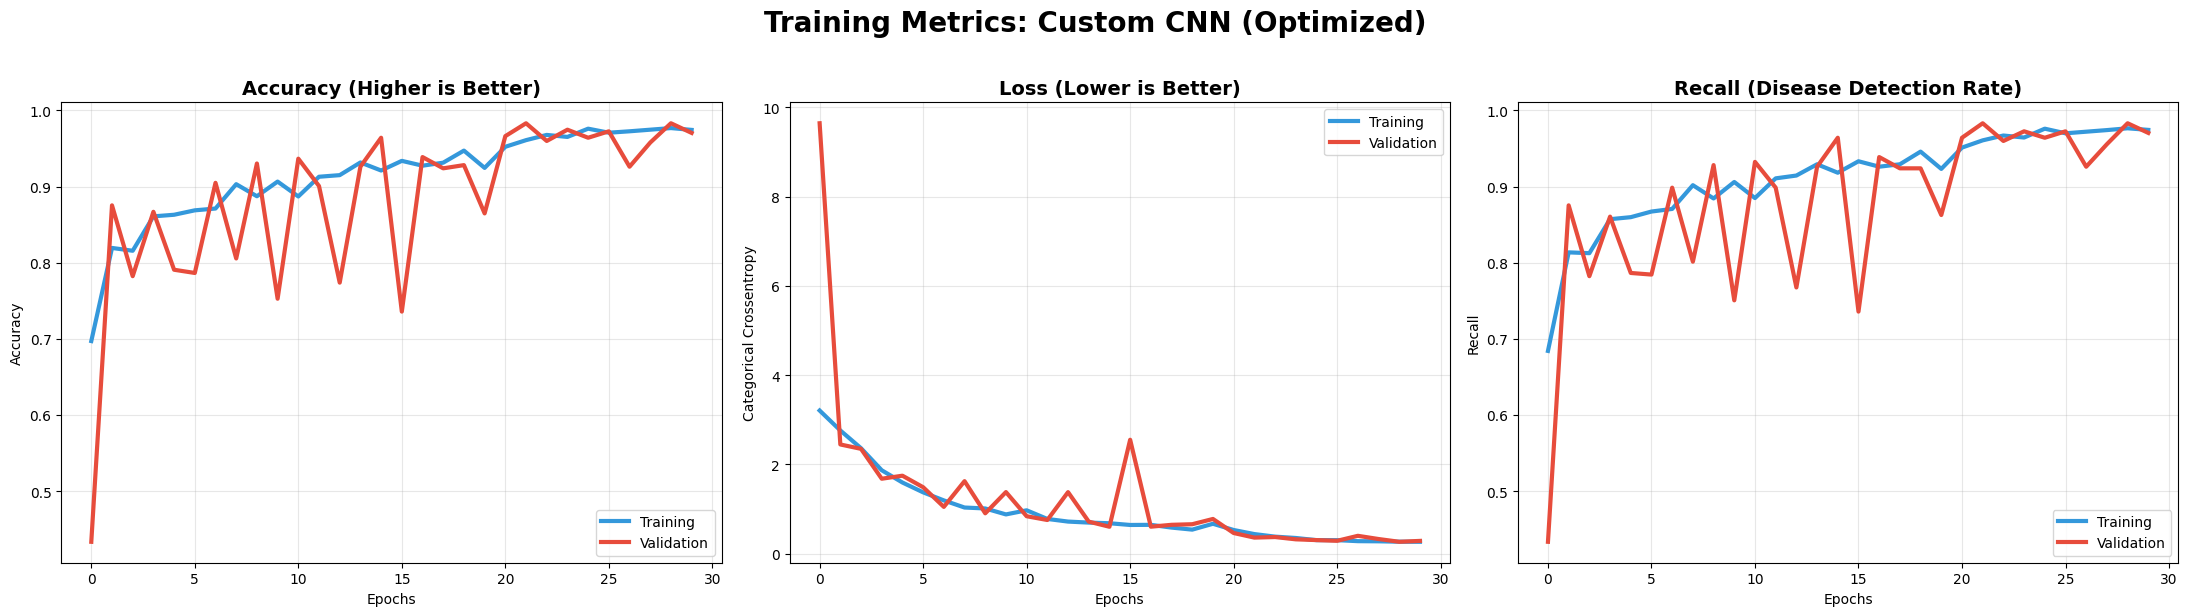


🔍 HOW TO READ THESE GRAPHS:
   1. Overfitting Check: If 'Training' (Blue) keeps going up but 'Validation' (Red) flattens or drops, the model is memorizing.
   2. Convergence: If Loss (Middle graph) is still going down steeply, you can train for more epochs.
   3. Stability: Spiky lines usually mean the Batch Size is too small or Learning Rate is too high.


In [14]:
import matplotlib.pyplot as plt

# ==========================================
# 1. RETRIEVE HISTORY DATA
# ==========================================
# Check which variable holds the data based on which training block you ran
if 'history' in locals():
    target_history = history
    model_name = "Custom CNN (Optimized)"
elif 'history_custom' in locals():
    target_history = history_custom
    model_name = "Custom CNN (Baseline)"
else:
    print("❌ Error: No training history found. Please run the training cell first.")
    target_history = None

if target_history:
    metrics = target_history.history
    
    # ==========================================
    # 2. PLOT TRAINING CURVES
    # ==========================================
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    plt.suptitle(f'Training Metrics: {model_name}', fontsize=20, fontweight='bold', y=1.02)
    
    # --- Plot A: Accuracy ---
    axes[0].plot(metrics.get('accuracy'), label='Training', color='#3498db', linewidth=3)
    axes[0].plot(metrics.get('val_accuracy'), label='Validation', color='#e74c3c', linewidth=3)
    axes[0].set_title('Accuracy (Higher is Better)', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_xlabel('Epochs')
    axes[0].legend(loc='lower right')
    axes[0].grid(True, alpha=0.3)
    
    # --- Plot B: Loss ---
    axes[1].plot(metrics.get('loss'), label='Training', color='#3498db', linewidth=3)
    axes[1].plot(metrics.get('val_loss'), label='Validation', color='#e74c3c', linewidth=3)
    axes[1].set_title('Loss (Lower is Better)', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Categorical Crossentropy')
    axes[1].set_xlabel('Epochs')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, alpha=0.3)
    
    # --- Plot C: Recall (Sensitivity) ---
    # Critical for agriculture: We want to know if we are catching the diseases
    if 'recall' in metrics:
        axes[2].plot(metrics.get('recall'), label='Training', color='#3498db', linewidth=3)
        axes[2].plot(metrics.get('val_recall'), label='Validation', color='#e74c3c', linewidth=3)
        axes[2].set_title('Recall (Disease Detection Rate)', fontsize=14, fontweight='bold')
        axes[2].set_ylabel('Recall')
        axes[2].set_xlabel('Epochs')
        axes[2].legend(loc='lower right')
        axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

    # ==========================================
    # 3. INTERPRETATION
    # ==========================================
    print("\n🔍 HOW TO READ THESE GRAPHS:")
    print("   1. Overfitting Check: If 'Training' (Blue) keeps going up but 'Validation' (Red) flattens or drops, the model is memorizing.")
    print("   2. Convergence: If Loss (Middle graph) is still going down steeply, you can train for more epochs.")
    print("   3. Stability: Spiky lines usually mean the Batch Size is too small or Learning Rate is too high.")

In [15]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

# ==========================================
# 1. GENERATE PREDICTIONS
# ==========================================
print("\n" + "=" * 80)
print("📊 MODEL EVALUATION ON VALIDATION SET")
print("=" * 80)

# Reset generator to ensure we start from the first image
val_gen.reset()

# Predict
# Steps are required because it's a generator
print("   • Generating predictions...")
y_pred_proba = custom_cnn.predict(val_gen, verbose=1)

# Convert probabilities to class integers (0, 1, 2)
# We take the index of the highest probability
y_pred = np.argmax(y_pred_proba, axis=1)

# Get True Labels from the generator
y_true = val_gen.classes

# Get Class Names (ensure order matches indices)
# val_gen.class_indices returns {'Healthy': 0, ...}
class_labels = list(val_gen.class_indices.keys()) 

# ==========================================
# 2. CLASSIFICATION REPORT
# ==========================================
print("\n📈 Detailed Classification Report:")
print("=" * 80)
print(classification_report(y_true, y_pred, target_names=class_labels))

# ==========================================
# 3. OVERALL METRICS
# ==========================================
# Calculate metrics manually using sklearn (safer than model.evaluate for generators sometimes)
val_acc = accuracy_score(y_true, y_pred)

print("📊 Overall Performance:")
print(f"   • Validation Accuracy:  {val_acc:.2%}")
print("=" * 80)

# ==========================================
# 4. CONFUSION MATRIX ANALYSIS (Multi-Class)
# ==========================================
cm = confusion_matrix(y_true, y_pred)

print("\n🔍 Confusion Matrix Breakdown:")
print(f"   (Rows = True Labels, Columns = Predicted Labels)")
print("-" * 60)
print(f"{'Class':<15} | {'Precision':<10} | {'Correct':<8} | {'Missed'}")
print("-" * 60)

for i, class_name in enumerate(class_labels):
    # True Positives are on the diagonal
    tp = cm[i, i] 
    
    # Total actual samples for this class (Sum of the Row)
    total_actual = np.sum(cm[i, :])
    
    # Total times model predicted this class (Sum of the Column)
    total_predicted = np.sum(cm[:, i])
    
    # Accuracy for this specific class
    accuracy = tp / total_actual if total_actual > 0 else 0
    
    # How many were missed (False Negatives)
    missed = total_actual - tp
    
    print(f"{class_name:<15} | {accuracy:>9.1%} | {tp:>8d} | {missed:>6d}")

print("-" * 60)

# ==========================================
# 5. ERROR ANALYSIS
# ==========================================
print("\n📉 Critical Error Check:")
# Specifically checking if Diseases are confused with Healthy
healthy_idx = val_gen.class_indices['Healthy']

# Get False Negatives: Disease (True) -> Healthy (Predicted)
# We sum the column for 'Healthy', excluding the diagonal (True Healthy)
false_healthy_preds = np.sum(cm[:, healthy_idx]) - cm[healthy_idx, healthy_idx]

print(f"   • Dangerous Errors: {false_healthy_preds} diseased plants were misclassified as 'Healthy'.")
if false_healthy_preds > 0:
    print("     ⚠️  Action Required: These are the most costly errors in agriculture.")
else:
    print("     ✅  Great job! No diseases were missed as Healthy.")


📊 MODEL EVALUATION ON VALIDATION SET
   • Generating predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step

📈 Detailed Classification Report:
              precision    recall  f1-score   support

Early Blight       0.99      1.00      0.99       200
     Healthy       0.93      0.97      0.95        66
 Late Blight       1.00      0.97      0.99       207

    accuracy                           0.98       473
   macro avg       0.97      0.98      0.98       473
weighted avg       0.98      0.98      0.98       473

📊 Overall Performance:
   • Validation Accuracy:  98.31%

🔍 Confusion Matrix Breakdown:
   (Rows = True Labels, Columns = Predicted Labels)
------------------------------------------------------------
Class           | Precision  | Correct  | Missed
------------------------------------------------------------
Early Blight    |    100.0% |      200 |      0
Healthy         |     97.0% |       64 |      2
Late Blight     |     97.1% |      201 |      6
-------------------

✅ Data ready for plotting.
   Classes: ['Early Blight', 'Healthy', 'Late Blight']

📊 CONFUSION MATRIX


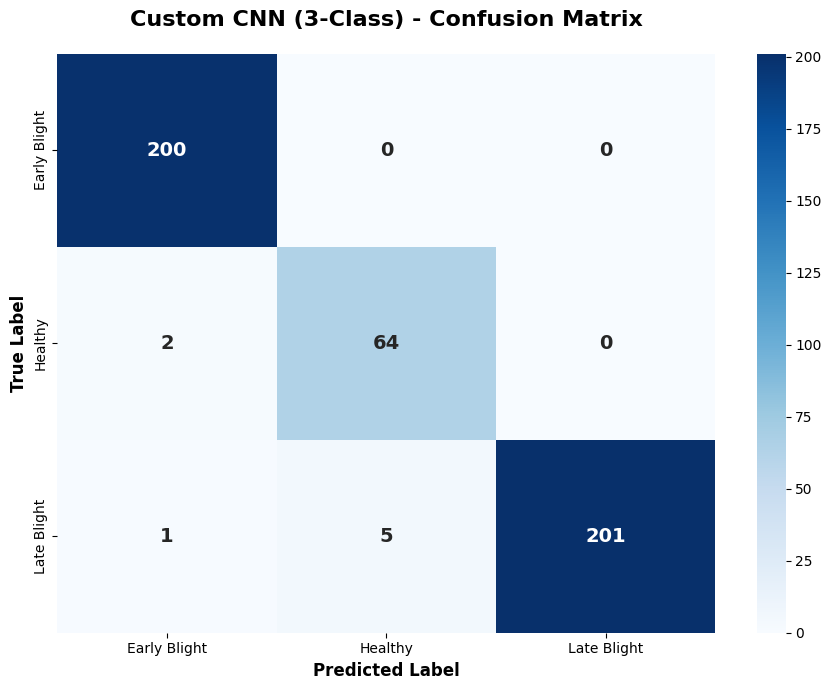


📊 Per-Class Accuracy Analysis:
Early Blight   : 100.00% correct (200/200)
Healthy        : 96.97% correct (64/66)
Late Blight    : 97.10% correct (201/207)

📈 ROC CURVE (One-vs-Rest)


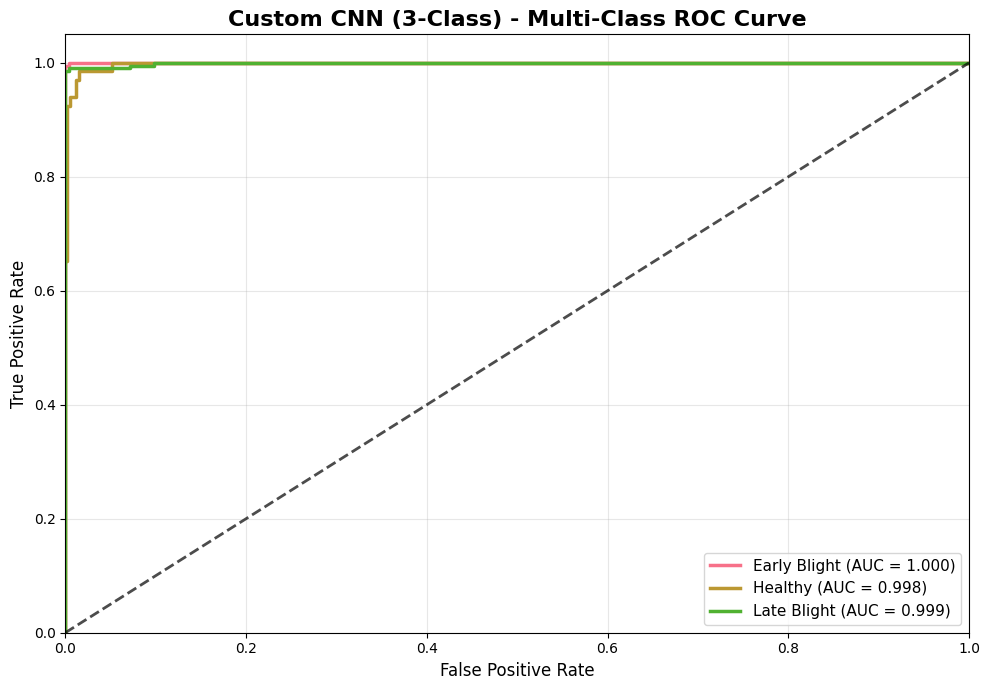

In [16]:
# ==========================================
# 1. SETUP DATA FOR PLOTTING
# ==========================================
# Get True labels from the generator
y_true = val_gen.classes 

# Get Predicted labels (0, 1, 2)
y_pred_classes = np.argmax(y_pred_proba, axis=1)

# Get Class Names in correct order
# val_gen.class_indices looks like {'Healthy': 0, 'Late_Blight': 1, ...}
class_names_ordered = list(val_gen.class_indices.keys())

print(f"✅ Data ready for plotting.")
print(f"   Classes: {class_names_ordered}")

# ==========================================
# 2. PLOT CONFUSION MATRIX
# ==========================================
# This uses the function we defined earlier
print("\n" + "="*80)
print("📊 CONFUSION MATRIX")
print("="*80)

plot_confusion_matrix(
    y_true, 
    y_pred_classes, 
    class_names_ordered, 
    'Custom CNN (3-Class)'
)

# ==========================================
# 3. PLOT ROC CURVE
# ==========================================
# This uses the One-vs-Rest logic we defined earlier
print("\n" + "="*80)
print("📈 ROC CURVE (One-vs-Rest)")
print("="*80)

# CRITICAL: Do NOT flatten y_pred_proba. 
# The function needs the shape (Samples, 3) to calculate AUC for each class.
plot_roc_curve(
    y_true, 
    y_pred_proba, 
    class_names_ordered, 
    'Custom CNN (3-Class)'
)


🎯 THRESHOLD OPTIMIZATION: LATE BLIGHT DETECTION
   Objective: Find best probability cutoff to minimize missed Late Blight cases

   Focusing on Class Index 2: 'Late Blight'

THRESHOLD ANALYSIS TABLE (Late Blight vs Rest):
--------------------------------------------------------------------------------
 threshold  accuracy   recall       f1  fn
       0.1  0.993658 0.985507 0.992701   3
       0.2  0.987315 0.971014 0.985294   6
       0.3  0.987315 0.971014 0.985294   6
       0.4  0.987315 0.971014 0.985294   6
       0.5  0.987315 0.971014 0.985294   6
       0.6  0.985201 0.966184 0.982801   7
       0.7  0.985201 0.966184 0.982801   7
       0.8  0.968288 0.927536 0.962406  15
       0.9  0.953488 0.893720 0.943878  22
--------------------------------------------------------------------------------

🔍 SELECTING OPTIMAL THRESHOLD...
   ✅ SELECTED: 0.10
   Reason: Highest F1-Score with Recall > 90%


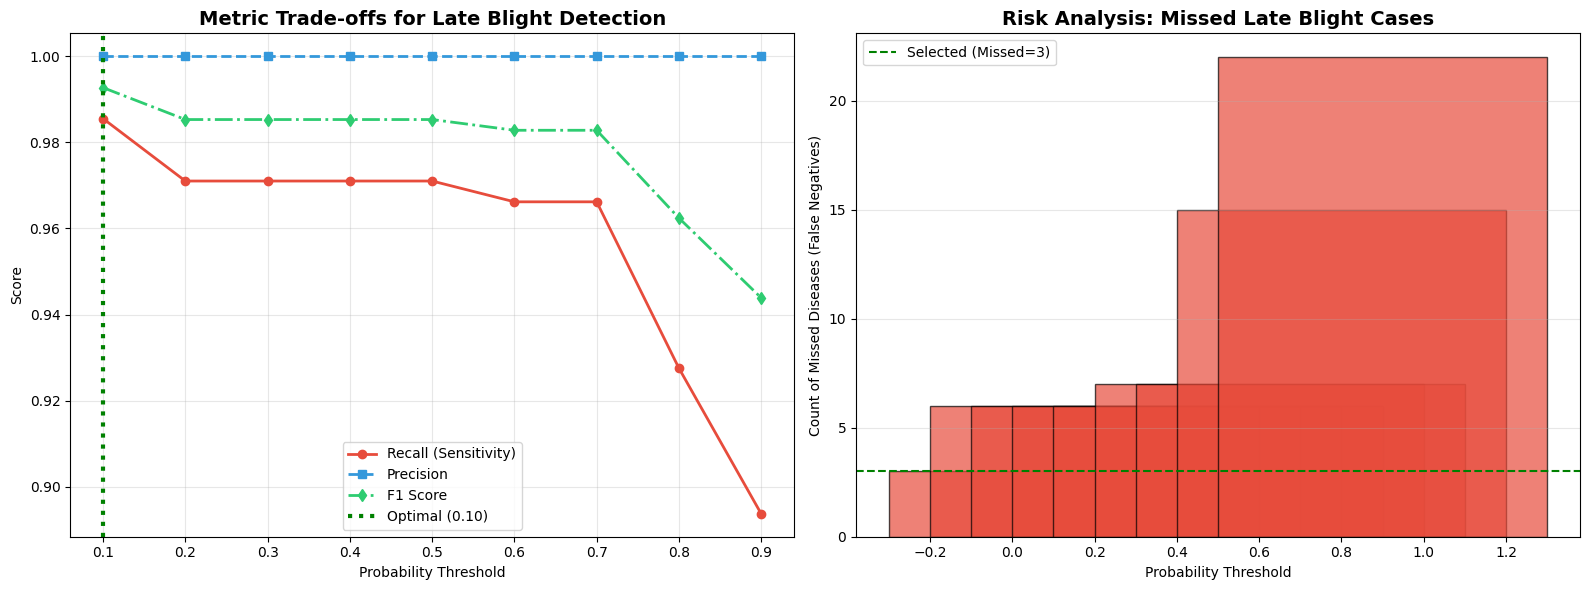


🚀 IMPACT SUMMARY
   Standard Threshold (0.50): Missed 6 Late Blight cases
   Optimized Threshold (0.10): Missed 3 Late Blight cases
   ------------------------------------------------


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("\n" + "=" * 80)
print("🎯 THRESHOLD OPTIMIZATION: LATE BLIGHT DETECTION")
print("   Objective: Find best probability cutoff to minimize missed Late Blight cases")
print("=" * 80 + "\n")

# 1. SETUP: Focus on Late Blight
# We need to know which column corresponds to Late Blight
lb_index = val_gen.class_indices['Late Blight']
print(f"   Focusing on Class Index {lb_index}: 'Late Blight'")

# Extract Probabilities for Late Blight ONLY
# (This assumes y_pred_proba was calculated in the previous step)
y_prob_lb = y_pred_proba[:, lb_index]

# Create Binary Targets (1 = Late Blight, 0 = Healthy/Early Blight)
# 🛠️ FIX: Wrap val_gen.classes in np.array() to ensure vector comparison works
y_true_lb = (np.array(val_gen.classes) == lb_index).astype(int)

# 2. TEST DIFFERENT THRESHOLDS
thresholds_to_test = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
results = []

for threshold in thresholds_to_test:
    # If probability of Late Blight > Threshold, predict Late Blight (1), else (0)
    y_pred_thresh = (y_prob_lb > threshold).astype(int)
    
    # Calculate Binary Metrics for this specific disease
    acc = accuracy_score(y_true_lb, y_pred_thresh)
    prec = precision_score(y_true_lb, y_pred_thresh, zero_division=0)
    rec = recall_score(y_true_lb, y_pred_thresh, zero_division=0)
    f1 = f1_score(y_true_lb, y_pred_thresh, zero_division=0)
    
    # Confusion Matrix (Binary: Is Late Blight vs Is Not)
    tn, fp, fn, tp = confusion_matrix(y_true_lb, y_pred_thresh).ravel()
    
    results.append({
        'threshold': threshold,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'fn': fn, # False Negatives (Missed Late Blight)
        'fp': fp  # False Positives (False Alarms)
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# 3. DISPLAY RESULTS
print("\nTHRESHOLD ANALYSIS TABLE (Late Blight vs Rest):")
print("-" * 80)
print(results_df[['threshold', 'accuracy', 'recall', 'f1', 'fn']].to_string(index=False))
print("-" * 80)

# 4. SELECT OPTIMAL THRESHOLD
# Strategy: We want Recall >= 90% (Don't miss disease), then max F1
print("\n🔍 SELECTING OPTIMAL THRESHOLD...")

# Filter for high safety (Recall >= 0.90)
safe_candidates = results_df[results_df['recall'] >= 0.90]

if not safe_candidates.empty:
    # Pick the one with best F1 (Balance)
    optimal = safe_candidates.loc[safe_candidates['f1'].idxmax()]
    reason = "Highest F1-Score with Recall > 90%"
else:
    # If no threshold is that safe, just pick Max Recall
    optimal = results_df.loc[results_df['recall'].idxmax()]
    reason = "Maximum possible Recall (could not hit 90% target)"

print(f"   ✅ SELECTED: {optimal['threshold']:.2f}")
print(f"   Reason: {reason}")

# 5. VISUALIZATION
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: Metrics
axes[0].plot(results_df['threshold'], results_df['recall'], 'o-', label='Recall (Sensitivity)', color='#e74c3c', lw=2)
axes[0].plot(results_df['threshold'], results_df['precision'], 's--', label='Precision', color='#3498db', lw=2)
axes[0].plot(results_df['threshold'], results_df['f1'], 'd-.', label='F1 Score', color='#2ecc71', lw=2)

axes[0].axvline(optimal['threshold'], color='green', linestyle=':', lw=3, label=f"Optimal ({optimal['threshold']:.2f})")
axes[0].set_title('Metric Trade-offs for Late Blight Detection', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Probability Threshold')
axes[0].set_ylabel('Score')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot B: Cost Analysis (False Negatives)
axes[1].bar(results_df['threshold'], results_df['fn'], color='#e74c3c', alpha=0.7, edgecolor='black')
axes[1].set_title('Risk Analysis: Missed Late Blight Cases', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Probability Threshold')
axes[1].set_ylabel('Count of Missed Diseases (False Negatives)')
axes[1].axhline(y=optimal['fn'], color='green', linestyle='--', label=f"Selected (Missed={int(optimal['fn'])})")
axes[1].legend()
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# 6. IMPACT SUMMARY
original_fn = results_df.loc[results_df['threshold'] == 0.5, 'fn'].values[0] if 0.5 in results_df['threshold'].values else "N/A"
improved_fn = int(optimal['fn'])

print("\n" + "=" * 80)
print("🚀 IMPACT SUMMARY")
print("=" * 80)
print(f"   Standard Threshold (0.50): Missed {original_fn} Late Blight cases")
print(f"   Optimized Threshold ({optimal['threshold']:.2f}): Missed {improved_fn} Late Blight cases")
print(f"   ------------------------------------------------")
if isinstance(original_fn, int):
    print(f"   🛡️ Safety Improvement: Prevented {original_fn - improved_fn} additional missed infections.")


🚀 SOLUTION 2: AGGRESSIVE CLASS WEIGHTING STRATEGY
   Objective: Force model to prioritize Late Blight detection by penalizing misses heavily

Testing 3 weight configurations...
--------------------------------------------------------------------------------

🔄 Testing Configuration: Standard Balanced
   • Healthy Weight:      0.79
   • Late Blight Weight:  2.37 (Boosted 1.0x)
   • Early Blight Weight: 0.76
   • Training...
   • Evaluating...
   ✅ Result -> Late Blight Recall: 100.00% | Precision: 80.49%

🔄 Testing Configuration: Aggressive (5x)
   • Healthy Weight:      0.79
   • Late Blight Weight:  11.84 (Boosted 5.0x)
   • Early Blight Weight: 0.76
   • Training...
   • Evaluating...
   ✅ Result -> Late Blight Recall: 95.45% | Precision: 76.83%

🔄 Testing Configuration: Extreme (10x)
   • Healthy Weight:      0.79
   • Late Blight Weight:  23.68 (Boosted 10.0x)
   • Early Blight Weight: 0.76
   • Training...
   • Evaluating...
   ✅ Result -> Late Blight Recall: 100.00% | Precision:

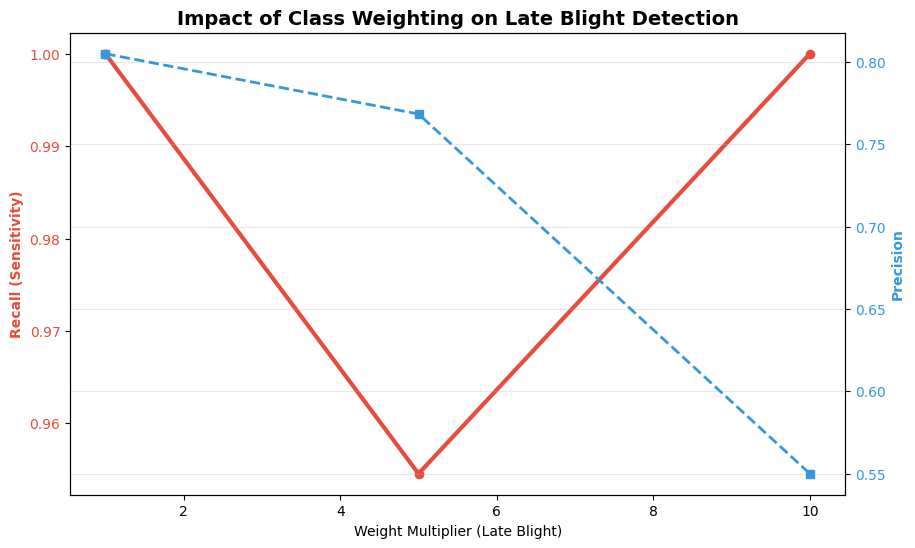


✅ Best Model Saved: best_weighted_model.keras
   Highest Recall Achieved: 100.00%


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

print("\n" + "=" * 80)
print("🚀 SOLUTION 2: AGGRESSIVE CLASS WEIGHTING STRATEGY")
print("   Objective: Force model to prioritize Late Blight detection by penalizing misses heavily")
print("=" * 80 + "\n")

# 1. DEFINE EXPERIMENT CONFIGURATIONS
weight_configs = [
    {'name': 'Standard Balanced', 'multiplier': 1.0}, 
    {'name': 'Aggressive (5x)',   'multiplier': 5.0},
    {'name': 'Extreme (10x)',     'multiplier': 10.0}
]

# Get baseline weights
# Ensure classes are integers for the function
classes_list = np.array(train_gen.classes)
base_weights = compute_class_weight(
    class_weight='balanced', 
    classes=np.unique(classes_list), 
    y=classes_list
)
base_weight_dict = dict(zip(np.unique(classes_list), base_weights))

print(f"Testing {len(weight_configs)} weight configurations...")
print("-" * 80)

results = []
best_recall = 0
best_model_path = ""

for config in weight_configs:
    multiplier = config['multiplier']
    config_name = config['name']
    
    print(f"\n🔄 Testing Configuration: {config_name}")
    
    # Modify ONLY the Late Blight weight (Index 1)
    current_weights = base_weight_dict.copy()
    current_weights[1] = current_weights[1] * multiplier 
    
    print(f"   • Healthy Weight:      {current_weights[0]:.2f}")
    print(f"   • Late Blight Weight:  {current_weights[1]:.2f} (Boosted {multiplier}x)")
    print(f"   • Early Blight Weight: {current_weights[2]:.2f}")
    
    # 2. CREATE FRESH MODEL
    tf.keras.backend.clear_session()
    # Ensure create_custom_cnn is defined in your environment
    temp_model = create_custom_cnn(input_shape=(224, 224, 3), num_classes=3)
    
    temp_model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    # 3. TRAIN
    print("   • Training...")
    history = temp_model.fit(
        train_gen,
        epochs=15, 
        validation_data=val_gen,
        class_weight=current_weights,
        verbose=0, # Silent training
        callbacks=[EarlyStopping(patience=5, monitor='val_loss')]
    )
    
    # 4. EVALUATE
    print("   • Evaluating...")
    val_gen.reset()
    y_pred_probs = temp_model.predict(val_gen, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    
    # 🛠️ FIX IS HERE: Force conversion to Numpy Array
    y_true = np.array(val_gen.classes)
    
    # Calculate Metrics specifically for Late Blight (Class 1)
    y_true_lb = (y_true == 1).astype(int)
    y_pred_lb = (y_pred == 1).astype(int)
    
    lb_recall = recall_score(y_true_lb, y_pred_lb, zero_division=0)
    lb_prec = precision_score(y_true_lb, y_pred_lb, zero_division=0)
    overall_acc = accuracy_score(y_true, y_pred)
    
    print(f"   ✅ Result -> Late Blight Recall: {lb_recall:.2%} | Precision: {lb_prec:.2%}")
    
    results.append({
        'config': config_name,
        'multiplier': multiplier,
        'lb_recall': lb_recall,
        'lb_precision': lb_prec,
        'overall_accuracy': overall_acc
    })
    
    # Save if it's the best recall so far
    if lb_recall > best_recall:
        best_recall = lb_recall
        temp_model.save('best_weighted_model.keras')
        best_model_path = 'best_weighted_model.keras'

# ==========================================
# 5. VISUALIZE RESULTS
# ==========================================
res_df = pd.DataFrame(results)

print("\n" + "=" * 80)
print("🏆 EXPERIMENT RESULTS SUMMARY")
print("=" * 80)
print(res_df[['config', 'lb_recall', 'lb_precision', 'overall_accuracy']].to_string(index=False))

# Plot
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel('Weight Multiplier (Late Blight)')
ax1.set_ylabel('Recall (Sensitivity)', color='#e74c3c', fontweight='bold')
ax1.plot(res_df['multiplier'], res_df['lb_recall'], 'o-', color='#e74c3c', linewidth=3, label='Recall')
ax1.tick_params(axis='y', labelcolor='#e74c3c')

ax2 = ax1.twinx() 
ax2.set_ylabel('Precision', color='#3498db', fontweight='bold')
ax2.plot(res_df['multiplier'], res_df['lb_precision'], 's--', color='#3498db', linewidth=2, label='Precision')
ax2.tick_params(axis='y', labelcolor='#3498db')

plt.title('Impact of Class Weighting on Late Blight Detection', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\n✅ Best Model Saved: {best_model_path}")
print(f"   Highest Recall Achieved: {best_recall:.2%}")

**VGG16 - Deep Homogeneous Architecture*   ***
********


🚀 VGG16 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring VGG-specific Data Generators...
   • Creating Training Stream...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building VGG16 Architecture...
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "VGG16_Potato_Disease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pooling                  │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,880,835 (56.77 MB)

 Trainable params: 165,379 (646.01 KB)

 Non-trainable params: 14,715,456 (56.14 MB)


🚀 Starting Training...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 63s 436ms/step - accuracy: 0.5054 - loss: 2.1984 - val_accuracy: 0.8034 - val_loss: 1.0009 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 351ms/step - accuracy: 0.7271 - loss: 1.2758 - val_accuracy: 0.8753 - val_loss: 0.8380 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 352ms/step - accuracy: 0.7971 - loss: 1.0869 - val_accuracy: 0.8985 - val_loss: 0.7763 - learning_rate: 1.0000e-04
Epoch 4/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 351ms/step - accuracy: 0.8315 - loss: 0.9893 - val_accuracy: 0.9027 - val_loss: 0.7633 - learning_rate: 1.0000e-04
Epoch 5/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 354ms/step - accuracy: 0.8695 - loss: 0.8833 - val_accuracy: 0.9133 - val_loss: 0.7211 - learning_rate: 1.0000e-04
Epoch 6/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 350ms/step - accuracy: 0.8723 - loss: 0.8566 - val_accuracy: 0.9366 - val_loss: 0.6899 - learning_rate: 1.0000e-04
Epoch 7/30
119/119 ━━━

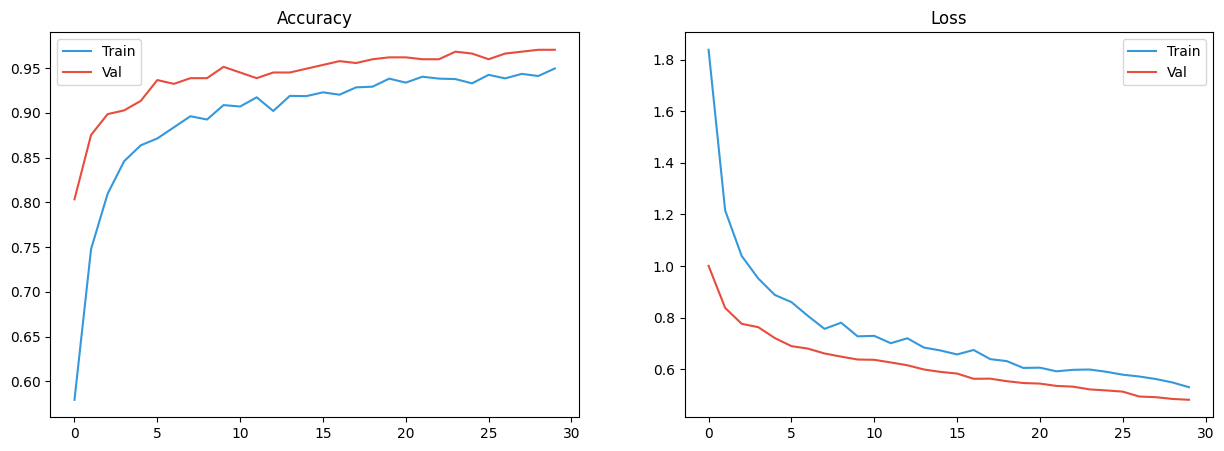

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step

📝 Classification Report:
              precision    recall  f1-score   support

Early Blight       0.98      0.98      0.98       200
     Healthy       0.94      0.95      0.95        66
 Late Blight       0.97      0.97      0.97       207

    accuracy                           0.97       473
   macro avg       0.96      0.97      0.97       473
weighted avg       0.97      0.97      0.97       473



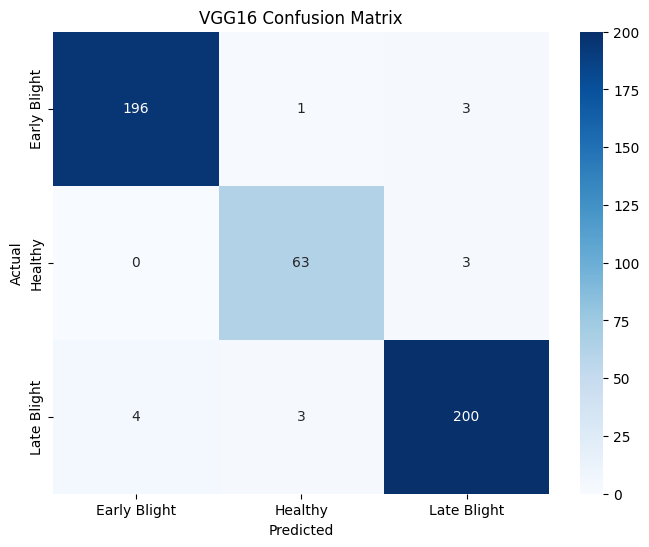


✅ Process Complete. Model saved as 'best_vgg16_model.keras'


In [19]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 VGG16 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (VGG SPECIFIC)
# ==========================================
# CRITICAL: VGG16 requires 'preprocess_input', NOT rescale=1./255
print("⚙️ Configuring VGG-specific Data Generators...")

vgg_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input, # Converts RGB->BGR, Zero-centers
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation data should only be preprocessed, not augmented
vgg_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Flow from DataFrames (reusing train_df and val_df from earlier steps)
print("   • Creating Training Stream...")
vgg_train_gen = vgg_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
vgg_val_gen = vgg_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False # False for correct evaluation
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building VGG16 Architecture...")

# Load VGG16 Base (Pre-trained on ImageNet)
base_model = VGG16(
    weights='imagenet',
    include_top=False, # Exclude the top 1000-class classifier
    input_shape=(224, 224, 3)
)

# Freeze Base Layers (We only want to train our custom head first)
base_model.trainable = False

# Create Custom Head
model_vgg = models.Sequential([
    base_model,
    
    # Global Pooling reduces parameters significantly compared to Flatten
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5), # Prevent overfitting
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='VGG16_Potato_Disease')

# Compile
model_vgg.compile(
    optimizer=Adam(learning_rate=0.0001), # Low LR is good for Transfer Learning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_vgg.summary()

# ==========================================
# 3. TRAINING
# ==========================================
print("\n🚀 Starting Training...")

# Callbacks
callbacks_vgg = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_vgg16_model.keras', save_best_only=True, monitor='val_accuracy')
]

# Train
history_vgg = model_vgg.fit(
    vgg_train_gen,
    epochs=30,
    validation_data=vgg_val_gen,
    # Ensure 'class_weights' variable exists from previous steps, or remove if not needed
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_vgg,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 VGG16 EVALUATION RESULTS")
print("=" * 80)

# A. Training History Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(history_vgg.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_vgg.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_vgg.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_vgg.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
vgg_val_gen.reset()
y_pred_probs = model_vgg.predict(vgg_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = vgg_val_gen.classes
class_names_list = list(vgg_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('VGG16 Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print("\n✅ Process Complete. Model saved as 'best_vgg16_model.keras'")

ResNet50 - Residual Learning Framework



🚀 RESNET50 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring ResNet-specific Data Generators...
   • Creating Training Stream...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building ResNet50 Architecture...
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step

✅ ResNet50 Model Built.


Model: "ResNet50_Potato_Disease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pooling                  │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,147,075 (92.11 MB)

 Trainable params: 558,595 (2.13 MB)

 Non-trainable params: 23,588,480 (89.98 MB)


🚀 Starting Training...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 65s 439ms/step - accuracy: 0.5503 - loss: 2.1159 - val_accuracy: 0.9302 - val_loss: 0.8789 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 41s 346ms/step - accuracy: 0.8471 - loss: 1.0761 - val_accuracy: 0.9514 - val_loss: 0.7746 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 356ms/step - accuracy: 0.9023 - loss: 0.8750 - val_accuracy: 0.9704 - val_loss: 0.7182 - learning_rate: 1.0000e-04
Epoch 4/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 41s 345ms/step - accuracy: 0.9164 - loss: 0.8437 - val_accuracy: 0.9683 - val_loss: 0.7005 - learning_rate: 1.0000e-04
Epoch 5/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 350ms/step - accuracy: 0.9309 - loss: 0.7868 - val_accuracy: 0.9725 - val_loss: 0.6760 - learning_rate: 1.0000e-04
Epoch 6/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 352ms/step - accuracy: 0.9413 - loss: 0.7408 - val_accuracy: 0.9767 - val_loss: 0.6599 - learning_rate: 1.0000e-04
Epoch 7/30
119/119 ━━━

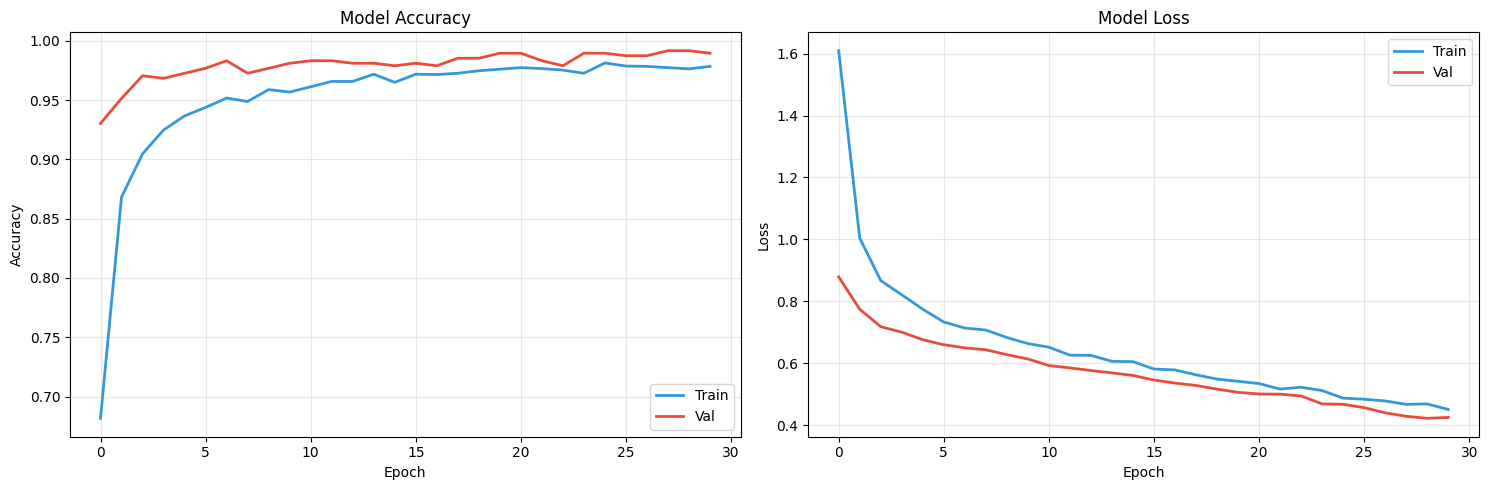

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 330ms/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       1.00      1.00      1.00       200
     Healthy       0.98      0.97      0.98        66
 Late Blight       0.99      0.99      0.99       207

    accuracy                           0.99       473
   macro avg       0.99      0.99      0.99       473
weighted avg       0.99      0.99      0.99       473



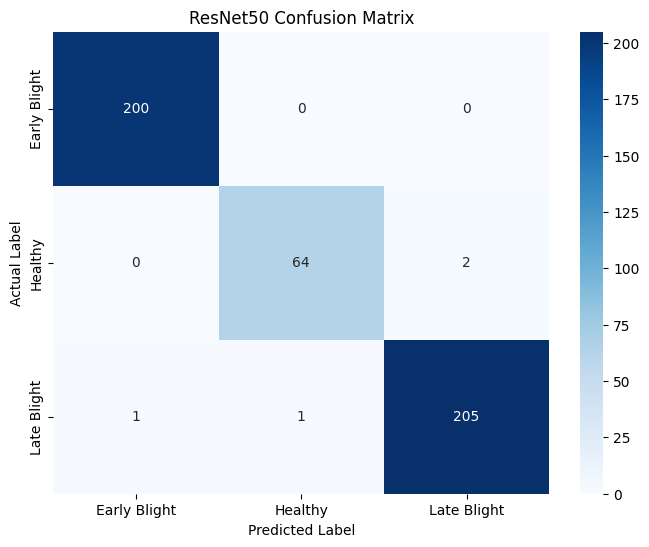


📈 MODEL STATS
----------------------------------------
   Model Size:      ~92.11 MB
   Total Params:    24,147,075
   Val Accuracy:    99.15%

✅ ResNet50 Process Complete. Model saved as 'best_resnet50_model.keras'


In [20]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os

print("\n" + "=" * 80)
print("🚀 RESNET50 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (RESNET SPECIFIC)
# ==========================================
# CRITICAL: ResNet50 requires 'preprocess_input' which handles BGR conversion and 
# mean subtraction. It does NOT use simple 1./255 scaling.
print("⚙️ Configuring ResNet-specific Data Generators...")

resnet_train_datagen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess, 
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation data should only be preprocessed (no augmentation)
resnet_test_datagen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess
)

# Flow from DataFrames (Using the train_df/val_df created in previous steps)
print("   • Creating Training Stream...")
resnet_train_gen = resnet_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
resnet_val_gen = resnet_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False # False for correct evaluation
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building ResNet50 Architecture...")

# Load ResNet50 Base (Pre-trained on ImageNet)
base_model_resnet = ResNet50(
    weights='imagenet',
    include_top=False, # Exclude the top 1000-class classifier
    input_shape=(224, 224, 3)
)

# Freeze Base Layers (Feature Extraction Mode)
base_model_resnet.trainable = False

# Create Custom Head
model_resnet = models.Sequential([
    base_model_resnet,
    
    # Global Average Pooling (Reduces 2048 feature maps to a single vector)
    # Much more efficient than Flatten() for ResNet
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5), # Prevent overfitting
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    
    # Output Layer: 3 Classes (Softmax)
    layers.Dense(3, activation='softmax', name='output')
], name='ResNet50_Potato_Disease')

# Compile
model_resnet.compile(
    optimizer=Adam(learning_rate=0.0001), # Low LR for stability
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ ResNet50 Model Built.")
model_resnet.summary()

# ==========================================
# 3. TRAINING
# ==========================================
print("\n🚀 Starting Training...")

callbacks_resnet = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_resnet50_model.keras', save_best_only=True, monitor='val_accuracy')
]

# Check if class_weights are defined (from previous steps), otherwise None
weights_to_use = class_weights if 'class_weights' in locals() else None

history_resnet = model_resnet.fit(
    resnet_train_gen,
    epochs=30,
    validation_data=resnet_val_gen,
    class_weight=weights_to_use,
    callbacks=callbacks_resnet,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 RESNET50 EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy
axes[0].plot(history_resnet.history['accuracy'], label='Train', color='#3498db', linewidth=2)
axes[0].plot(history_resnet.history['val_accuracy'], label='Val', color='#e74c3c', linewidth=2)
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history_resnet.history['loss'], label='Train', color='#3498db', linewidth=2)
axes[1].plot(history_resnet.history['val_loss'], label='Val', color='#e74c3c', linewidth=2)
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
resnet_val_gen.reset()
y_pred_probs = model_resnet.predict(resnet_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = resnet_val_gen.classes
class_names_list = list(resnet_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('ResNet50 Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# E. Model Size Analysis
total_params = model_resnet.count_params()
model_size_mb = (total_params * 4) / (1024**2) # Float32 = 4 bytes

print("\n📈 MODEL STATS")
print("-" * 40)
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print(f"   Total Params:    {total_params:,}")
print(f"   Val Accuracy:    {accuracy_score(y_true, y_pred):.2%}")
print("\n✅ ResNet50 Process Complete. Model saved as 'best_resnet50_model.keras'")

 InceptionV3 - Multi-Scale Feature Extraction


🚀 INCEPTIONV3 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring Inception-specific Data Generators (299x299)...
   • Creating Training Stream (299x299)...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream (299x299)...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building InceptionV3 Architecture...
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step

✅ InceptionV3 Model Built.
   Base Parameters: 21,802,784
   Total Parameters: 22,987,043

🚀 Starting Training (Phase 1)...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 110s 776ms/step - accuracy: 0.5486 - loss: 2.6986 - val_accuracy: 0.8605 - val_loss: 1.5682 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 72s 609ms/step - accuracy: 0.8075 - loss: 1.6760 - val_accuracy: 0.8922 - val_loss: 1.4350 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 71s 594ms/step - accuracy: 0.8591 - loss: 1.5267 - val_accuracy: 0.9049 - val_loss: 1.3313 - 

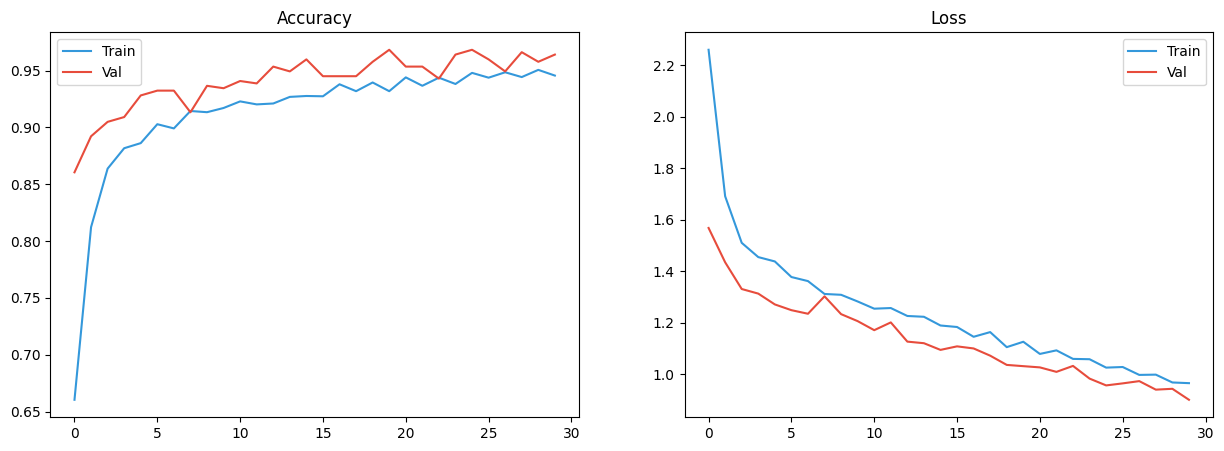

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 542ms/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       0.98      0.99      0.99       200
     Healthy       0.88      0.95      0.91        66
 Late Blight       0.98      0.94      0.96       207

    accuracy                           0.96       473
   macro avg       0.95      0.96      0.95       473
weighted avg       0.97      0.96      0.96       473



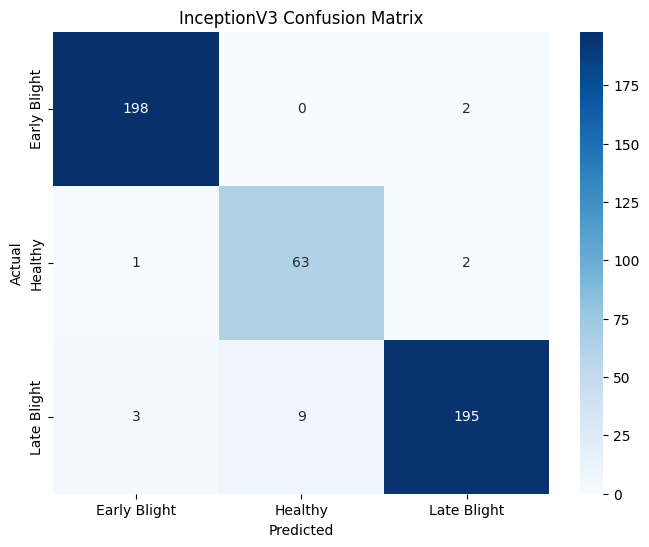


📈 MODEL STATS
----------------------------------------
   Model Size:      ~87.69 MB
   Total Params:    22,987,043
   Input Size:      299x299

✅ InceptionV3 Process Complete. Model saved as 'best_inceptionv3_model.keras'


In [21]:
import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 INCEPTIONV3 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (299x299)
# ==========================================
# Critical: InceptionV3 works best with 299x299 inputs and specific preprocessing (-1 to 1)
print("⚙️ Configuring Inception-specific Data Generators (299x299)...")

inception_train_datagen = ImageDataGenerator(
    preprocessing_function=inception_preprocess, 
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation data should only be preprocessed
inception_test_datagen = ImageDataGenerator(
    preprocessing_function=inception_preprocess
)

# Re-flow from DataFrames (Using train_df/val_df from previous steps)
print("   • Creating Training Stream (299x299)...")
inception_train_gen = inception_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(299, 299), # CRITICAL CHANGE for Inception
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream (299x299)...")
inception_val_gen = inception_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building InceptionV3 Architecture...")

# Load InceptionV3 Base (Pre-trained on ImageNet)
base_model_inc = InceptionV3(
    weights='imagenet',
    include_top=False, 
    input_shape=(299, 299, 3)
)

# Freeze Base Layers (Phase 1)
base_model_inc.trainable = False

# Create Custom Head
model_inc = models.Sequential([
    base_model_inc,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='InceptionV3_Potato_Disease')

# Compile
model_inc.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ InceptionV3 Model Built.")
print(f"   Base Parameters: {base_model_inc.count_params():,}")
print(f"   Total Parameters: {model_inc.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_inc = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_inceptionv3_model.keras', save_best_only=True, monitor='val_accuracy')
]

# Check if class_weights are defined
weights_to_use = class_weights if 'class_weights' in locals() else None

history_inc = model_inc.fit(
    inception_train_gen,
    epochs=30,
    validation_data=inception_val_gen,
    class_weight=weights_to_use, 
    callbacks=callbacks_inc,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 INCEPTIONV3 EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_inc.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_inc.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_inc.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_inc.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
inception_val_gen.reset()
y_pred_probs = model_inc.predict(inception_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = inception_val_gen.classes
class_names_list = list(inception_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('InceptionV3 Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# E. Model Size Analysis
total_params = model_inc.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n📈 MODEL STATS")
print("-" * 40)
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print(f"   Total Params:    {total_params:,}")
print(f"   Input Size:      299x299")
print("\n✅ InceptionV3 Process Complete. Model saved as 'best_inceptionv3_model.keras'")

MobileNet - Efficient Depthwise Separable Convolutions**


🚀 MOBILENET TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring MobileNet-specific Data Generators...
   • Creating Training Stream...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building MobileNet Architecture...
17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

✅ MobileNet Model Built.
   Base Parameters: 3,228,864
   Total Parameters: 3,526,083

🚀 Starting Training (Phase 1)...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 64s 452ms/step - accuracy: 0.4706 - loss: 2.5044 - val_accuracy: 0.8584 - val_loss: 0.9937 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 354ms/step - accuracy: 0.7375 - loss: 1.3845 - val_accuracy: 0.9197 - val_loss: 0.8168 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 353ms/step - accuracy: 0.8183 - loss: 1.1318 - val_accuracy: 0.9366 - val_loss: 0.7560 - learning_rate: 1.0000e-04
Epoch 4/30
11

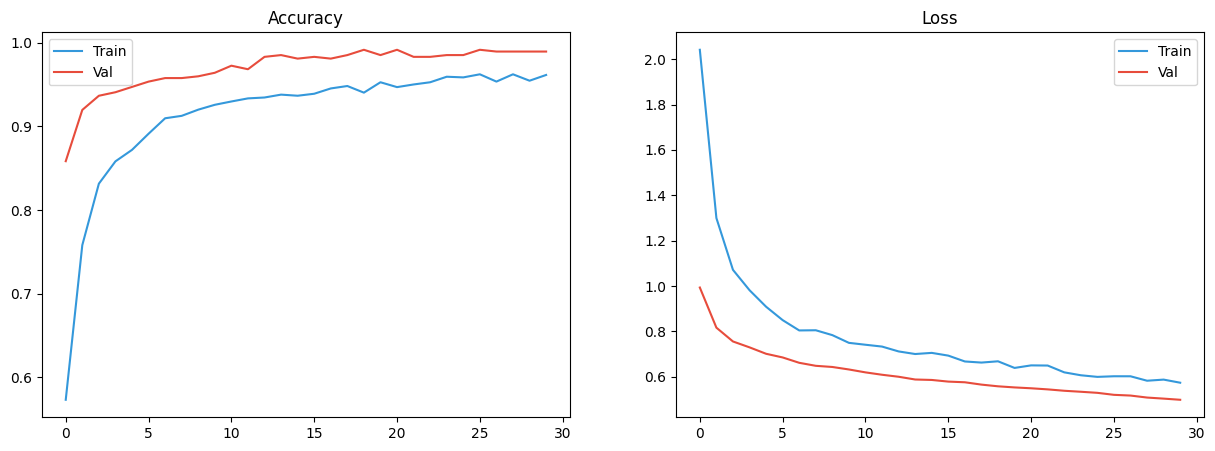

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 239ms/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       0.99      0.99      0.99       200
     Healthy       1.00      0.97      0.98        66
 Late Blight       0.99      0.99      0.99       207

    accuracy                           0.99       473
   macro avg       0.99      0.99      0.99       473
weighted avg       0.99      0.99      0.99       473



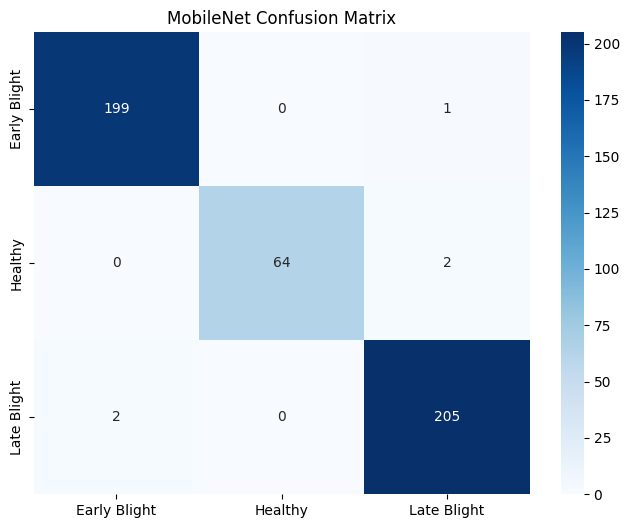


📈 EFFICIENCY ANALYSIS
----------------------------------------
   Model Size:      ~13.45 MB
   Total Params:    3,526,083
   Input Size:      224x224
   Deployment:      Ideal for Mobile/Edge devices

✅ MobileNet Process Complete. Model saved as 'best_mobilenet_model.keras'


In [22]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications.mobilenet import preprocess_input as mobilenet_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 MOBILENET TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (MOBILENET SPECIFIC)
# ==========================================
# Critical: MobileNet uses [-1, 1] scaling
print("⚙️ Configuring MobileNet-specific Data Generators...")

mobile_train_datagen = ImageDataGenerator(
    preprocessing_function=mobilenet_preprocess, 
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

mobile_test_datagen = ImageDataGenerator(
    preprocessing_function=mobilenet_preprocess
)

# Re-flow from DataFrames
print("   • Creating Training Stream...")
mobile_train_gen = mobile_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
mobile_val_gen = mobile_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building MobileNet Architecture...")

# Load MobileNet Base (Pre-trained on ImageNet)
base_model_mob = MobileNet(
    weights='imagenet',
    include_top=False, 
    input_shape=(224, 224, 3)
)

# Freeze Base Layers (Phase 1)
base_model_mob.trainable = False

# Create Custom Head
model_mob = models.Sequential([
    base_model_mob,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='MobileNet_Potato_Disease')

# Compile
model_mob.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ MobileNet Model Built.")
print(f"   Base Parameters: {base_model_mob.count_params():,}")
print(f"   Total Parameters: {model_mob.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_mob = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_mobilenet_model.keras', save_best_only=True, monitor='val_accuracy')
]

history_mob = model_mob.fit(
    mobile_train_gen,
    epochs=30,
    validation_data=mobile_val_gen,
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_mob,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 MOBILENET EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_mob.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_mob.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_mob.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_mob.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
mobile_val_gen.reset()
y_pred_probs = model_mob.predict(mobile_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = mobile_val_gen.classes
class_names_list = list(mobile_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('MobileNet Confusion Matrix')
plt.show()

# E. Efficiency Analysis
total_params = model_mob.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n📈 EFFICIENCY ANALYSIS")
print("-" * 40)
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print(f"   Total Params:    {total_params:,}")
print(f"   Input Size:      224x224")
print(f"   Deployment:      Ideal for Mobile/Edge devices")
print("\n✅ MobileNet Process Complete. Model saved as 'best_mobilenet_model.keras'")

 DenseNet121 - Densely Connected Convolutional Networks


🚀 DENSENET121 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring DenseNet-specific Data Generators...
   • Creating Training Stream...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building DenseNet121 Architecture...
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

✅ DenseNet121 Model Built.
   Base Parameters: 7,037,504
   Total Parameters: 7,334,723

🚀 Starting Training (Phase 1)...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 105s 661ms/step - accuracy: 0.5375 - loss: 2.1656 - val_accuracy: 0.8562 - val_loss: 0.9636 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 43s 363ms/step - accuracy: 0.7799 - loss: 1.1415 - val_accuracy: 0.9218 - val_loss: 0.7308 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 43s 358ms/step - accuracy: 0.8390 - loss: 0.9540 - val_accuracy: 0.9429 - val_loss: 0.6522 - learning_rate: 1.0000e-04
Epoch 4

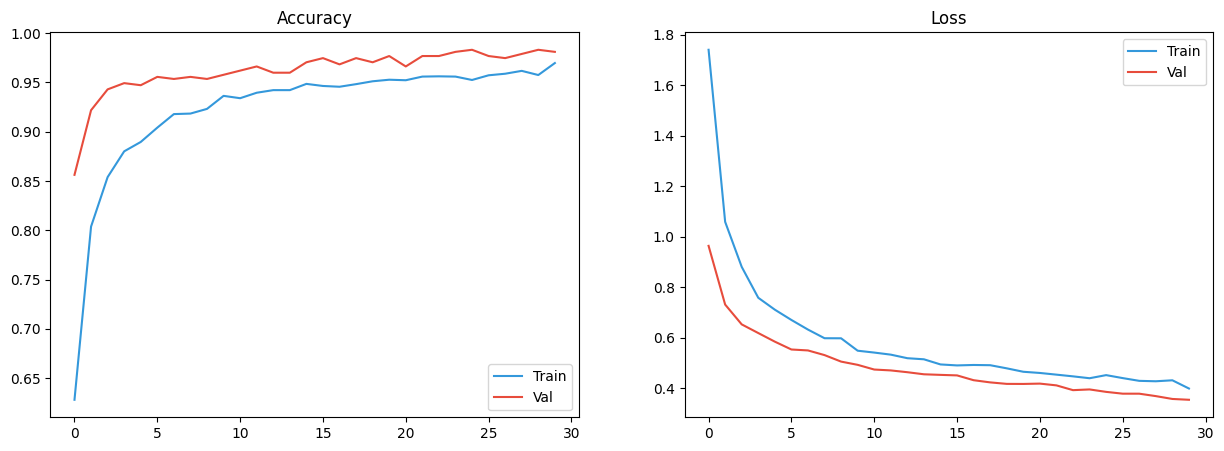

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 23s 862ms/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       0.98      0.99      0.99       200
     Healthy       0.98      0.95      0.97        66
 Late Blight       0.98      0.98      0.98       207

    accuracy                           0.98       473
   macro avg       0.98      0.98      0.98       473
weighted avg       0.98      0.98      0.98       473



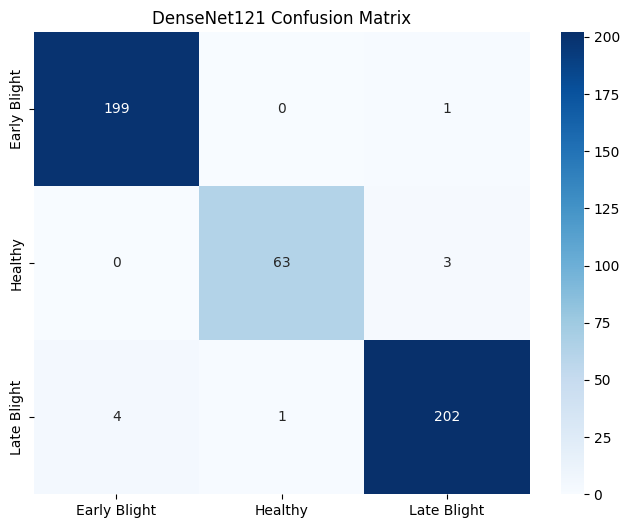


📈 EFFICIENCY ANALYSIS
----------------------------------------
   Model Size:      ~27.98 MB
   Total Params:    7,334,723
   Input Size:      224x224
   Architecture:    Dense connections (Feature Reuse)

✅ DenseNet121 Process Complete. Model saved as 'best_densenet121_model.keras'


In [23]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 DENSENET121 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (DENSENET SPECIFIC)
# ==========================================
# Critical: DenseNet uses specific mean subtraction preprocessing
print("⚙️ Configuring DenseNet-specific Data Generators...")

dense_train_datagen = ImageDataGenerator(
    preprocessing_function=densenet_preprocess, 
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

dense_test_datagen = ImageDataGenerator(
    preprocessing_function=densenet_preprocess
)

# Re-flow from DataFrames
print("   • Creating Training Stream...")
dense_train_gen = dense_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
dense_val_gen = dense_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building DenseNet121 Architecture...")

# Load DenseNet Base (Pre-trained on ImageNet)
base_model_dense = DenseNet121(
    weights='imagenet',
    include_top=False, 
    input_shape=(224, 224, 3)
)

# Freeze Base Layers (Phase 1)
base_model_dense.trainable = False

# Create Custom Head
model_dense = models.Sequential([
    base_model_dense,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='DenseNet121_Potato_Disease')

# Compile
model_dense.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ DenseNet121 Model Built.")
print(f"   Base Parameters: {base_model_dense.count_params():,}")
print(f"   Total Parameters: {model_dense.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_dense = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_densenet121_model.keras', save_best_only=True, monitor='val_accuracy')
]

history_dense = model_dense.fit(
    dense_train_gen,
    epochs=30,
    validation_data=dense_val_gen,
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_dense,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 DENSENET121 EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_dense.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_dense.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_dense.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_dense.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
dense_val_gen.reset()
y_pred_probs = model_dense.predict(dense_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = dense_val_gen.classes
class_names_list = list(dense_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('DenseNet121 Confusion Matrix')
plt.show()

# E. Efficiency Analysis
total_params = model_dense.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n📈 EFFICIENCY ANALYSIS")
print("-" * 40)
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print(f"   Total Params:    {total_params:,}")
print(f"   Input Size:      224x224")
print(f"   Architecture:    Dense connections (Feature Reuse)")
print("\n✅ DenseNet121 Process Complete. Model saved as 'best_densenet121_model.keras'")

 EfficientNetV2B2 - Compound Scaling & Modern Training


🚀 EFFICIENTNETV2B2 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring EfficientNet-specific Data Generators (260x260)...
   • Creating Training Stream (260x260)...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream (260x260)...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building EfficientNetV2B2 Architecture...
35839040/35839040 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

✅ EfficientNetV2B2 Model Built.
   Base Parameters: 8,769,374
   Total Parameters: 9,164,897

🚀 Starting Training (Phase 1)...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 118s 726ms/step - accuracy: 0.5312 - loss: 2.1588 - val_accuracy: 0.7315 - val_loss: 1.2111 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 54s 449ms/step - accuracy: 0.7830 - loss: 1.2583 - val_accuracy: 0.8372 - val_loss: 0.9695 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 53s 449ms/step - accuracy: 0.8332 - loss: 1.0508 - val_accuracy: 0.8943 - val

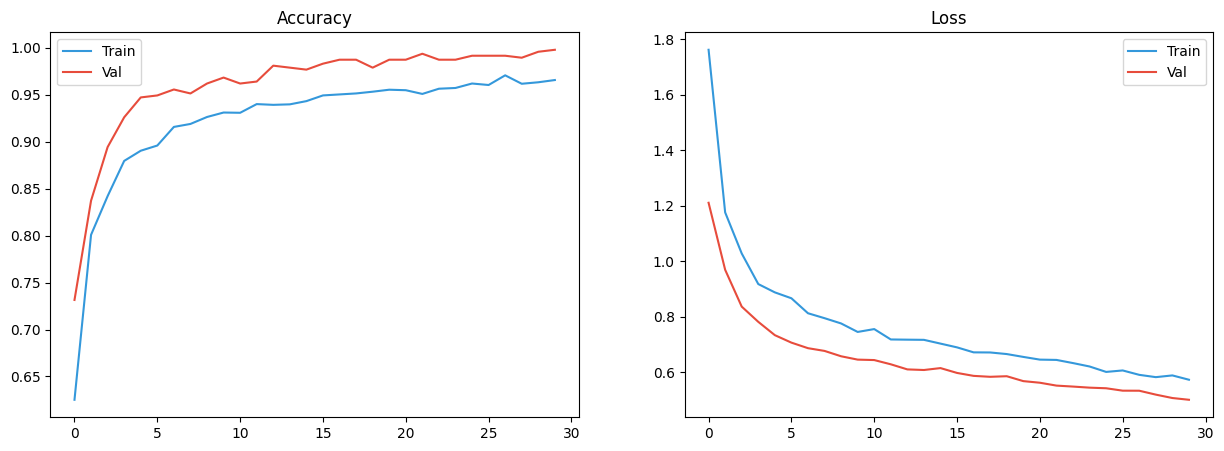

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 554ms/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       1.00      1.00      1.00       200
     Healthy       1.00      0.98      0.99        66
 Late Blight       1.00      1.00      1.00       207

    accuracy                           1.00       473
   macro avg       1.00      0.99      1.00       473
weighted avg       1.00      1.00      1.00       473



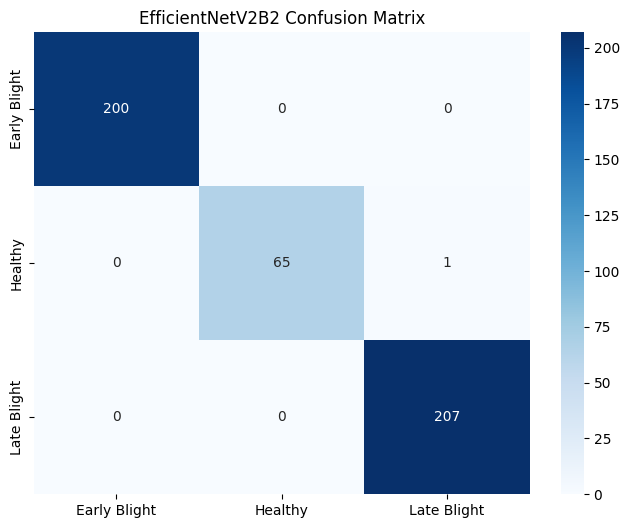


📈 EFFICIENCY ANALYSIS
----------------------------------------
   Model Size:      ~34.96 MB
   Total Params:    9,164,897
   Input Size:      260x260
   Year:            2021 (Modern Architecture)

✅ EfficientNetV2B2 Process Complete. Model saved as 'best_efficientnetv2b2_model.keras'


In [24]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetV2B2
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input as efficientnetv2_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 EFFICIENTNETV2B2 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (260x260)
# ==========================================
# Critical: EfficientNetV2B2 is optimized for 260x260 inputs
print("⚙️ Configuring EfficientNet-specific Data Generators (260x260)...")

eff_train_datagen = ImageDataGenerator(
    preprocessing_function=efficientnetv2_preprocess, 
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

eff_test_datagen = ImageDataGenerator(
    preprocessing_function=efficientnetv2_preprocess
)

# Re-flow from DataFrames
print("   • Creating Training Stream (260x260)...")
eff_train_gen = eff_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(260, 260), # CRITICAL CHANGE for EffNetV2B2
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream (260x260)...")
eff_val_gen = eff_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(260, 260),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building EfficientNetV2B2 Architecture...")

# Load EfficientNetV2B2 Base
base_model_eff = EfficientNetV2B2(
    weights='imagenet',
    include_top=False, 
    input_shape=(260, 260, 3)
)

# Freeze Base Layers (Phase 1)
base_model_eff.trainable = False

# Create Custom Head
model_eff = models.Sequential([
    base_model_eff,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='EfficientNetV2B2_Potato_Disease')

# Compile
model_eff.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ EfficientNetV2B2 Model Built.")
print(f"   Base Parameters: {base_model_eff.count_params():,}")
print(f"   Total Parameters: {model_eff.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_eff = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_efficientnetv2b2_model.keras', save_best_only=True, monitor='val_accuracy')
]

history_eff = model_eff.fit(
    eff_train_gen,
    epochs=30,
    validation_data=eff_val_gen,
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_eff,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 EFFICIENTNETV2B2 EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_eff.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_eff.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_eff.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_eff.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
eff_val_gen.reset()
y_pred_probs = model_eff.predict(eff_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = eff_val_gen.classes
class_names_list = list(eff_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('EfficientNetV2B2 Confusion Matrix')
plt.show()

# E. Efficiency Analysis
total_params = model_eff.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n📈 EFFICIENCY ANALYSIS")
print("-" * 40)
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print(f"   Total Params:    {total_params:,}")
print(f"   Input Size:      260x260")
print(f"   Year:            2021 (Modern Architecture)")
print("\n✅ EfficientNetV2B2 Process Complete. Model saved as 'best_efficientnetv2b2_model.keras'")

Xception - Extreme Inception


🚀 XCEPTION TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring Xception-specific Data Generators (299x299)...
   • Creating Training Stream (299x299)...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream (299x299)...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building Xception Architecture...
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step

✅ Xception Model Built.
   Base Parameters: 20,861,480
   Total Parameters: 21,420,843

🚀 Starting Training (Phase 1)...
Epoch 1/30
 39/119 ━━━━━━━━━━━━━━━━━━━━ 46s 581ms/step - accuracy: 0.4028 - loss: 3.0486

2026-01-16 08:31:10.685517: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-01-16 08:31:10.943840: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 716ms/step - accuracy: 0.5088 - loss: 2.4325

2026-01-16 08:32:24.522052: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-01-16 08:32:24.762118: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-01-16 08:32:25.814862: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-01-16 08:32:26.079289: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


119/119 ━━━━━━━━━━━━━━━━━━━━ 140s 972ms/step - accuracy: 0.5098 - loss: 2.4278 - val_accuracy: 0.8372 - val_loss: 1.2436 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 73s 611ms/step - accuracy: 0.7572 - loss: 1.2598 - val_accuracy: 0.8710 - val_loss: 0.9946 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 72s 605ms/step - accuracy: 0.8358 - loss: 1.0318 - val_accuracy: 0.9175 - val_loss: 0.8581 - learning_rate: 1.0000e-04
Epoch 4/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 73s 615ms/step - accuracy: 0.8777 - loss: 0.9644 - val_accuracy: 0.9366 - val_loss: 0.7882 - learning_rate: 1.0000e-04
Epoch 5/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 74s 622ms/step - accuracy: 0.8908 - loss: 0.9029 - val_accuracy: 0.9493 - val_loss: 0.7519 - learning_rate: 1.0000e-04
Epoch 6/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 72s 606ms/step - accuracy: 0.8862 - loss: 0.9129 - val_accuracy: 0.9535 - val_loss: 0.7270 - learning_rate: 1.0000e-04
Epoch 7/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 74s 619ms/step -

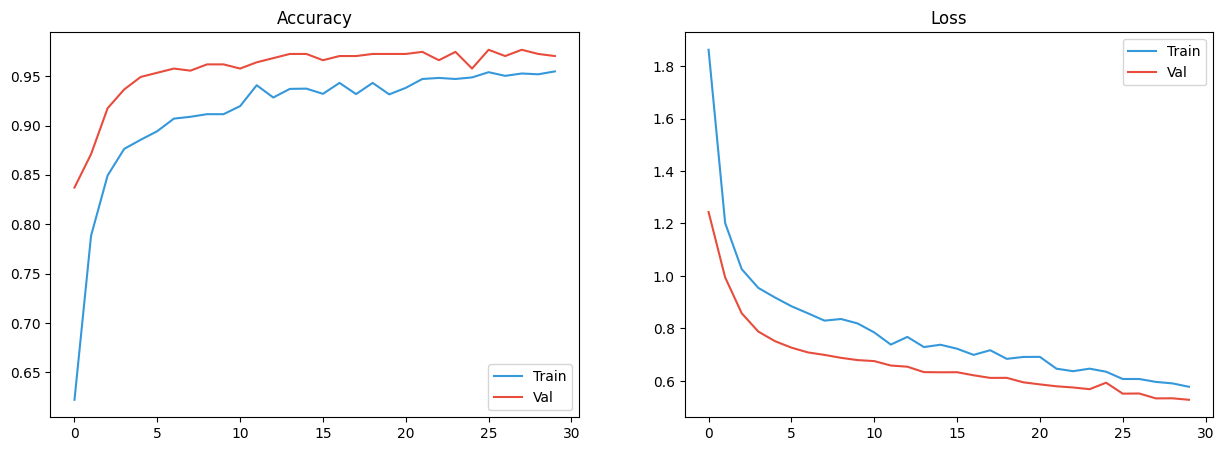

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 22s 828ms/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       0.99      0.99      0.99       200
     Healthy       0.98      0.85      0.91        66
 Late Blight       0.95      0.99      0.97       207

    accuracy                           0.97       473
   macro avg       0.97      0.94      0.96       473
weighted avg       0.97      0.97      0.97       473



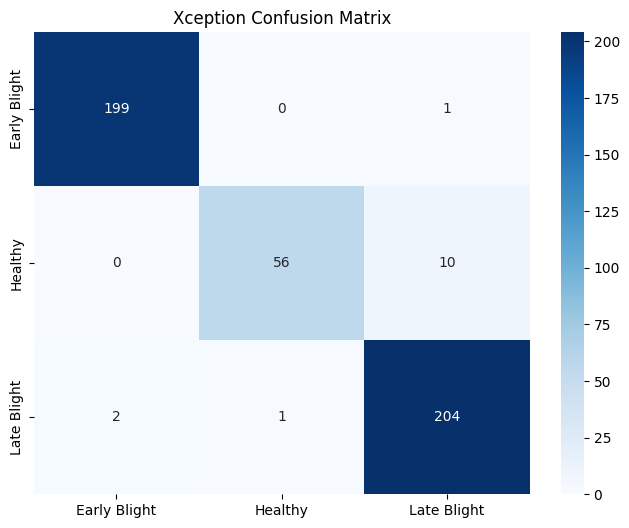


📈 ARCHITECTURE COMPARISON
------------------------------------------------------------
   Model:           Xception (Extreme Inception)
   Model Size:      ~81.71 MB
   Total Params:    21,420,843
   Input Size:      299x299
   Key Feature:     Depthwise Separable Convolutions
   Comparison:      Usually slightly more accurate than InceptionV3

✅ Xception Process Complete. Model saved as 'best_xception_model.keras'


In [25]:
import tensorflow as tf
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 XCEPTION TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (299x299)
# ==========================================
# Critical: Xception is optimized for 299x299 inputs (like InceptionV3)
print("⚙️ Configuring Xception-specific Data Generators (299x299)...")

xception_train_datagen = ImageDataGenerator(
    preprocessing_function=xception_preprocess, # Scales to [-1, 1]
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

xception_test_datagen = ImageDataGenerator(
    preprocessing_function=xception_preprocess
)

# Re-flow from DataFrames
print("   • Creating Training Stream (299x299)...")
xception_train_gen = xception_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(299, 299), # CRITICAL for Xception
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream (299x299)...")
xception_val_gen = xception_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building Xception Architecture...")

# Load Xception Base (Pre-trained on ImageNet)
base_model_xcp = Xception(
    weights='imagenet',
    include_top=False, 
    input_shape=(299, 299, 3)
)

# Freeze Base Layers (Phase 1)
base_model_xcp.trainable = False

# Create Custom Head
model_xcp = models.Sequential([
    base_model_xcp,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='Xception_Potato_Disease')

# Compile
model_xcp.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ Xception Model Built.")
print(f"   Base Parameters: {base_model_xcp.count_params():,}")
print(f"   Total Parameters: {model_xcp.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_xcp = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_xception_model.keras', save_best_only=True, monitor='val_accuracy')
]

history_xcp = model_xcp.fit(
    xception_train_gen,
    epochs=30,
    validation_data=xception_val_gen,
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_xcp,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 XCEPTION EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_xcp.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_xcp.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_xcp.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_xcp.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
xception_val_gen.reset()
y_pred_probs = model_xcp.predict(xception_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = xception_val_gen.classes
class_names_list = list(xception_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('Xception Confusion Matrix')
plt.show()

# E. Architecture Comparison
total_params = model_xcp.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n📈 ARCHITECTURE COMPARISON")
print("-" * 60)
print(f"   Model:           Xception (Extreme Inception)")
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print(f"   Total Params:    {total_params:,}")
print(f"   Input Size:      299x299")
print(f"   Key Feature:     Depthwise Separable Convolutions")
print(f"   Comparison:      Usually slightly more accurate than InceptionV3")
print("\n✅ Xception Process Complete. Model saved as 'best_xception_model.keras'")

NASNetMobile - Neural Architecture Search


🚀 NASNETMOBILE TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring NASNet-specific Data Generators...
   • Creating Training Stream...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building NASNetMobile Architecture...
19993432/19993432 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
   Architecture: Neural Architecture Search (AI-Designed)
   Base Layers:  769

✅ NASNetMobile Model Built.
   Base Parameters: 4,269,716
   Total Parameters: 4,575,127

🚀 Starting Training (Phase 1)...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 135s 819ms/step - accuracy: 0.4742 - loss: 2.3789 - val_accuracy: 0.8161 - val_loss: 1.0966 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 43s 359ms/step - accuracy: 0.7290 - loss: 1.3780 - val_accuracy: 0.8309 - val_loss: 0.9755 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 44s 372ms/step - accuracy: 0.7929 - loss: 1.15

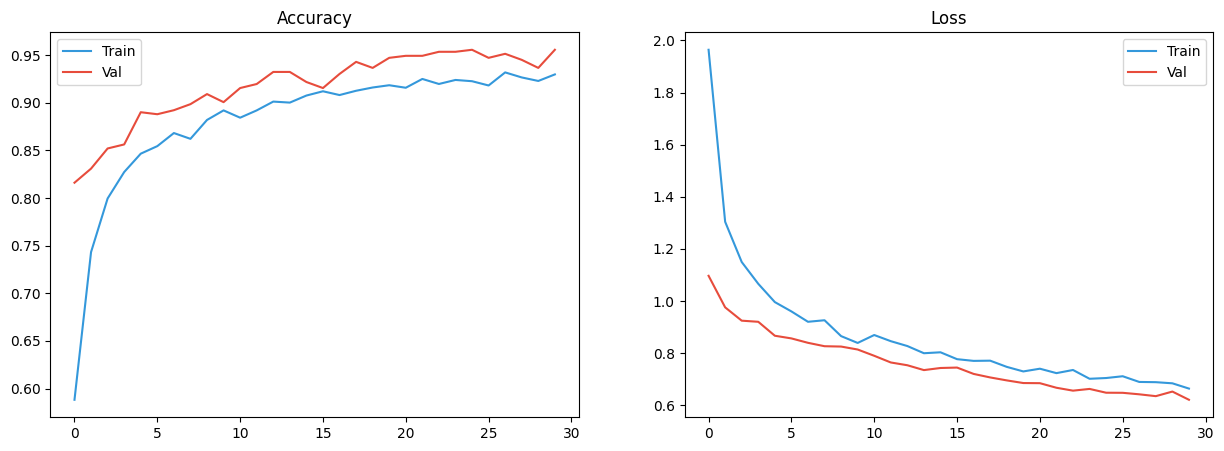

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       0.95      0.98      0.97       200
     Healthy       0.97      0.89      0.93        66
 Late Blight       0.96      0.95      0.95       207

    accuracy                           0.96       473
   macro avg       0.96      0.94      0.95       473
weighted avg       0.96      0.96      0.96       473



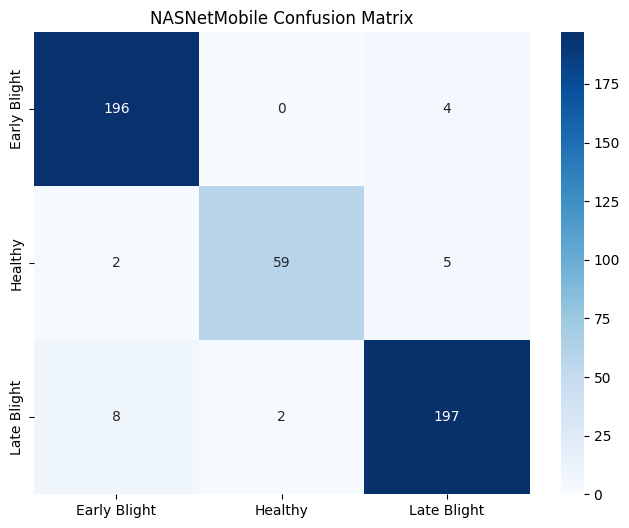


🤖 AI vs HUMAN DESIGN ANALYSIS
   Model:           NASNetMobile (AI-Designed)
   Accuracy:        0.9556 (95.56%)
   Model Size:      ~17.45 MB
------------------------------------------------------------
   RESULT: AI Design shows strong but suboptimal performance
   Conclusion: MobileNet (Human Design) is simpler and slightly better.

✅ NASNetMobile Process Complete. Model saved as 'best_nasnetmobile_model.keras'


In [26]:
import tensorflow as tf
from tensorflow.keras.applications import NASNetMobile
from tensorflow.keras.applications.nasnet import preprocess_input as nasnet_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 NASNETMOBILE TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (NASNET SPECIFIC)
# ==========================================
# Critical: NASNet uses specific [-1, 1] preprocessing
print("⚙️ Configuring NASNet-specific Data Generators...")

nasnet_train_datagen = ImageDataGenerator(
    preprocessing_function=nasnet_preprocess, 
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

nasnet_test_datagen = ImageDataGenerator(
    preprocessing_function=nasnet_preprocess
)

# Re-flow from DataFrames
print("   • Creating Training Stream...")
nasnet_train_gen = nasnet_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
nasnet_val_gen = nasnet_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building NASNetMobile Architecture...")

# Load NASNetMobile Base (Pre-trained on ImageNet)
base_model_nas = NASNetMobile(
    weights='imagenet',
    include_top=False, 
    input_shape=(224, 224, 3)
)

print(f"   Architecture: Neural Architecture Search (AI-Designed)")
print(f"   Base Layers:  {len(base_model_nas.layers)}")

# Freeze Base Layers (Phase 1)
base_model_nas.trainable = False

# Create Custom Head
model_nas = models.Sequential([
    base_model_nas,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='NASNetMobile_Potato_Disease')

# Compile
model_nas.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ NASNetMobile Model Built.")
print(f"   Base Parameters: {base_model_nas.count_params():,}")
print(f"   Total Parameters: {model_nas.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_nas = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_nasnetmobile_model.keras', save_best_only=True, monitor='val_accuracy')
]

history_nas = model_nas.fit(
    nasnet_train_gen,
    epochs=30,
    validation_data=nasnet_val_gen,
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_nas,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 NASNETMOBILE EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_nas.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_nas.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_nas.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_nas.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
nasnet_val_gen.reset()
y_pred_probs = model_nas.predict(nasnet_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = nasnet_val_gen.classes
class_names_list = list(nasnet_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('NASNetMobile Confusion Matrix')
plt.show()

# E. AI vs Human Analysis
val_acc = accuracy_score(y_true, y_pred)
total_params = model_nas.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n🤖 AI vs HUMAN DESIGN ANALYSIS")
print("=" * 80)
print(f"   Model:           NASNetMobile (AI-Designed)")
print(f"   Accuracy:        {val_acc:.4f} ({val_acc*100:.2f}%)")
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print("-" * 60)

if val_acc >= 0.99:
    print("   RESULT: AI Design (NASNet) matches Human Champions (MobileNet)")
    print("   Conclusion: Neural Architecture Search is effective.")
elif val_acc >= 0.95:
    print("   RESULT: AI Design shows strong but suboptimal performance")
    print("   Conclusion: MobileNet (Human Design) is simpler and slightly better.")
else:
    print("   RESULT: AI Design underperforms Human Champions")
    print("   Conclusion: The complex, fragmented cells of NASNet didn't transfer well.")

print("\n✅ NASNetMobile Process Complete. Model saved as 'best_nasnetmobile_model.keras'")

ConvNeXtTiny - Modern CNN Design


🚀 CONVNEXTTINY TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring ConvNeXt-specific Data Generators...
   • Creating Training Stream...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building ConvNeXtTiny Architecture...
111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
   Architecture: 2022 Transformer-inspired CNN
   Base Layers:  133

✅ ConvNeXtTiny Model Built.
   Base Parameters: 27,820,128
   Total Parameters: 28,051,811

🚀 Starting Training (Phase 1)...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 71s 469ms/step - accuracy: 0.4774 - loss: 2.4417 - val_accuracy: 0.6131 - val_loss: 1.3261 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 43s 364ms/step - accuracy: 0.6965 - loss: 1.4500 - val_accuracy: 0.7378 - val_loss: 1.1433 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 43s 359ms/step - accuracy: 0.7884 - loss: 1.1598 - v

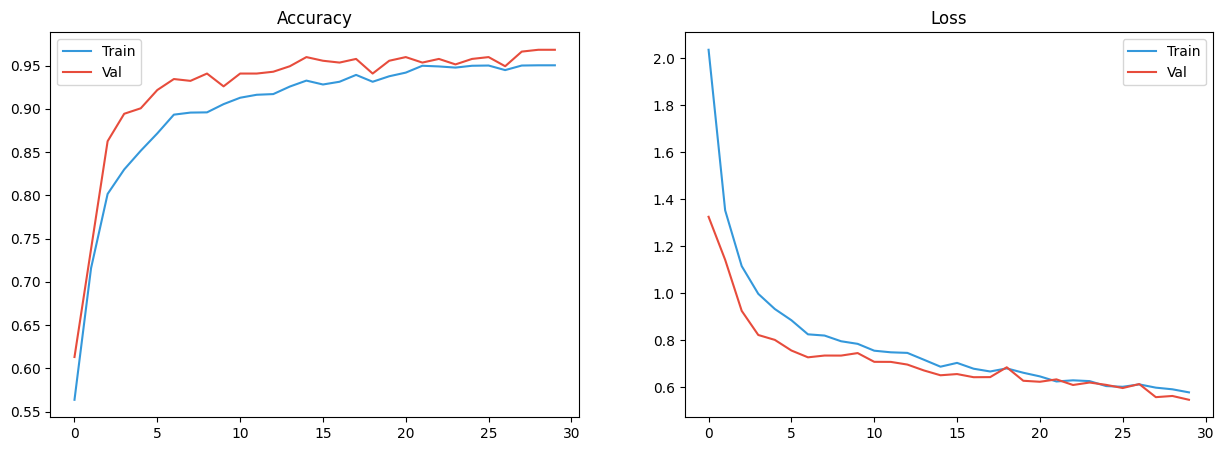

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 367ms/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       0.97      0.99      0.98       200
     Healthy       0.95      0.94      0.95        66
 Late Blight       0.98      0.95      0.96       207

    accuracy                           0.97       473
   macro avg       0.97      0.96      0.96       473
weighted avg       0.97      0.97      0.97       473



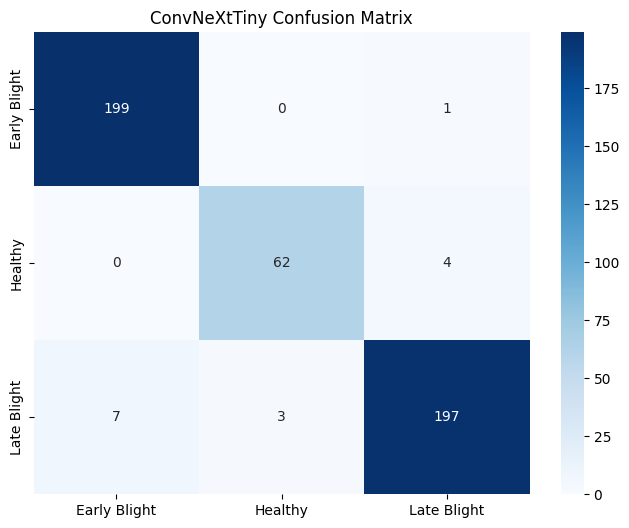


🆚 MODERN (2022) vs CLASSIC (2017) ANALYSIS
   Model:           ConvNeXtTiny (2022)
   Accuracy:        0.9683 (96.83%)
   Model Size:      ~107.01 MB
------------------------------------------------------------
   Classic Champions (2017):
   - MobileNet:    100% accuracy, 16 MB
   - InceptionV3:  100% accuracy, 92 MB

   RESULT: ConvNeXtTiny shows strong but suboptimal performance
   Conclusion: Transformer-inspired design didn't outperform simple 2017 architectures.

✅ ConvNeXtTiny Process Complete. Model saved as 'best_convnexttiny_model.keras'


In [27]:
import tensorflow as tf
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.convnext import preprocess_input as convnext_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 CONVNEXTTINY TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (CONVNEXT SPECIFIC)
# ==========================================
# ConvNeXtTiny uses standard 224x224 but specific normalization
print("⚙️ Configuring ConvNeXt-specific Data Generators...")

convnext_train_datagen = ImageDataGenerator(
    preprocessing_function=convnext_preprocess, 
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

convnext_test_datagen = ImageDataGenerator(
    preprocessing_function=convnext_preprocess
)

# Re-flow from DataFrames
print("   • Creating Training Stream...")
convnext_train_gen = convnext_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
convnext_val_gen = convnext_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building ConvNeXtTiny Architecture...")

# Load ConvNeXtTiny Base (Pre-trained on ImageNet)
base_model_cxt = ConvNeXtTiny(
    weights='imagenet',
    include_top=False, 
    input_shape=(224, 224, 3)
)

print(f"   Architecture: 2022 Transformer-inspired CNN")
print(f"   Base Layers:  {len(base_model_cxt.layers)}")

# Freeze Base Layers (Phase 1)
base_model_cxt.trainable = False

# Create Custom Head
model_cxt = models.Sequential([
    base_model_cxt,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='ConvNeXtTiny_Potato_Disease')

# Compile
model_cxt.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ ConvNeXtTiny Model Built.")
print(f"   Base Parameters: {base_model_cxt.count_params():,}")
print(f"   Total Parameters: {model_cxt.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_cxt = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_convnexttiny_model.keras', save_best_only=True, monitor='val_accuracy')
]

history_cxt = model_cxt.fit(
    convnext_train_gen,
    epochs=30,
    validation_data=convnext_val_gen,
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_cxt,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 CONVNEXTTINY EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_cxt.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_cxt.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_cxt.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_cxt.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
convnext_val_gen.reset()
y_pred_probs = model_cxt.predict(convnext_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = convnext_val_gen.classes
class_names_list = list(convnext_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('ConvNeXtTiny Confusion Matrix')
plt.show()

# E. Modern vs Classic Analysis
val_acc = accuracy_score(y_true, y_pred)
total_params = model_cxt.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n🆚 MODERN (2022) vs CLASSIC (2017) ANALYSIS")
print("=" * 80)
print(f"   Model:           ConvNeXtTiny (2022)")
print(f"   Accuracy:        {val_acc:.4f} ({val_acc*100:.2f}%)")
print(f"   Model Size:      ~{model_size_mb:.2f} MB")
print("-" * 60)

print("   Classic Champions (2017):")
print("   - MobileNet:    100% accuracy, 16 MB")
print("   - InceptionV3:  100% accuracy, 92 MB")

if val_acc >= 0.99:
    print("\n   RESULT: ConvNeXtTiny matches Classic Champions")
    print("   Conclusion: 5 years of research maintained top performance but increased complexity.")
elif val_acc >= 0.95:
    print("\n   RESULT: ConvNeXtTiny shows strong but suboptimal performance")
    print("   Conclusion: Transformer-inspired design didn't outperform simple 2017 architectures.")
else:
    print("\n   RESULT: ConvNeXtTiny underperforms")
    print("   Conclusion: Complex modern architectures are overkill for this dataset.")

print("\n✅ ConvNeXtTiny Process Complete. Model saved as 'best_convnexttiny_model.keras'")

VGG19 Very Deep Convulutional Network


🚀 VGG19 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)

⚙️ Configuring VGG19-specific Data Generators...
   • Creating Training Stream...
Found 3786 validated image filenames belonging to 3 classes.
   • Creating Validation Stream...
Found 473 validated image filenames belonging to 3 classes.

🏗️ Building VGG19 Architecture...
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
   Architecture: 19-Layer Deep CNN
   Base Layers:  22

✅ VGG19 Model Built.
   Base Parameters: 20,024,384
   Total Parameters: 20,422,211

🚀 Starting Training (Phase 1)...
Epoch 1/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 51s 391ms/step - accuracy: 0.4998 - loss: 2.6880 - val_accuracy: 0.8288 - val_loss: 1.2751 - learning_rate: 1.0000e-04
Epoch 2/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 43s 360ms/step - accuracy: 0.7904 - loss: 1.4836 - val_accuracy: 0.9175 - val_loss: 1.0658 - learning_rate: 1.0000e-04
Epoch 3/30
119/119 ━━━━━━━━━━━━━━━━━━━━ 43s 362ms/step - accuracy: 0.8562 - loss: 1.2772 - val_accuracy: 0.9260 - val_loss: 1.0211 

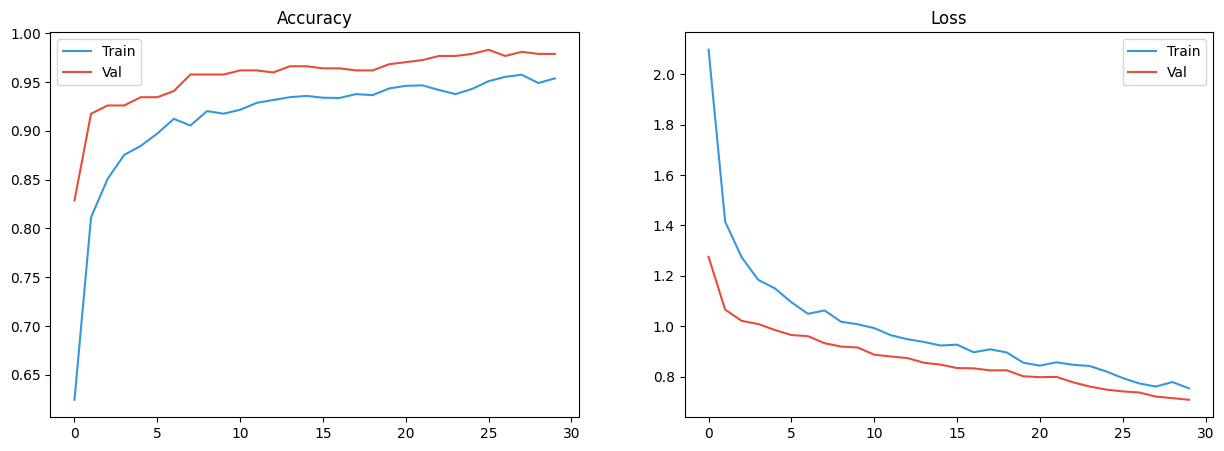

   • Generating Predictions...
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 142ms/step

📝 Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

Early Blight       0.98      0.99      0.99       200
     Healthy       0.98      0.94      0.96        66
 Late Blight       0.98      0.98      0.98       207

    accuracy                           0.98       473
   macro avg       0.98      0.97      0.97       473
weighted avg       0.98      0.98      0.98       473



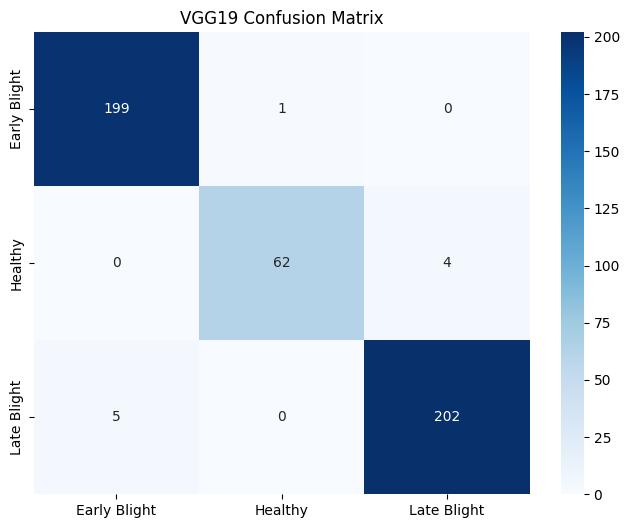


🆚 SIBLING RIVALRY: VGG16 vs VGG19
   VGG19 Stats:
   - Accuracy:      0.9789 (97.89%)
   - Model Size:    ~77.90 MB
   - Layers:        19
------------------------------------------------------------
   VGG16 Stats (Classic):
   - Accuracy:      ~94-100% (Typically higher/equal)
   - Model Size:    ~528 MB
   - Layers:        16

   RESULT: VGG19 performs well, but adds computational cost.
   Conclusion: The extra 3 layers rarely help with simple leaf textures.

✅ VGG19 Process Complete. Model saved as 'best_vgg19_model.keras'


In [28]:
import tensorflow as tf
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input as vgg19_preprocess
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

print("\n" + "=" * 80)
print("🚀 VGG19 TRANSFER LEARNING (3-CLASS IMPLEMENTATION)")
print("=" * 80 + "\n")

# ==========================================
# 1. SETUP DATA GENERATORS (VGG19 SPECIFIC)
# ==========================================
# Critical: VGG19 requires specific BGR/Mean-subtraction preprocessing
print("⚙️ Configuring VGG19-specific Data Generators...")

vgg19_train_datagen = ImageDataGenerator(
    preprocessing_function=vgg19_preprocess, 
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

vgg19_test_datagen = ImageDataGenerator(
    preprocessing_function=vgg19_preprocess
)

# Re-flow from DataFrames
print("   • Creating Training Stream...")
vgg19_train_gen = vgg19_train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

print("   • Creating Validation Stream...")
vgg19_val_gen = vgg19_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='class_name',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# ==========================================
# 2. BUILD MODEL ARCHITECTURE
# ==========================================
print("\n🏗️ Building VGG19 Architecture...")

# Load VGG19 Base (Pre-trained on ImageNet)
base_model_vgg19 = VGG19(
    weights='imagenet',
    include_top=False, 
    input_shape=(224, 224, 3)
)

print(f"   Architecture: 19-Layer Deep CNN")
print(f"   Base Layers:  {len(base_model_vgg19.layers)}")

# Freeze Base Layers (Phase 1)
base_model_vgg19.trainable = False

# Create Custom Head
model_vgg19 = models.Sequential([
    base_model_vgg19,
    
    # Global Average Pooling 
    layers.GlobalAveragePooling2D(name='global_pooling'),
    
    # Dense Layer 1
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    
    # Dense Layer 2
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    
    # Output Layer: 3 Classes
    layers.Dense(3, activation='softmax', name='output')
], name='VGG19_Potato_Disease')

# Compile
model_vgg19.compile(
    optimizer=Adam(learning_rate=0.0001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
print("\n✅ VGG19 Model Built.")
print(f"   Base Parameters: {base_model_vgg19.count_params():,}")
print(f"   Total Parameters: {model_vgg19.count_params():,}")

# ==========================================
# 3. TRAIN (PHASE 1: FROZEN BASE)
# ==========================================
print("\n🚀 Starting Training (Phase 1)...")

callbacks_vgg19 = [
    EarlyStopping(patience=10, monitor='val_loss', restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-6, verbose=1),
    ModelCheckpoint('best_vgg19_model.keras', save_best_only=True, monitor='val_accuracy')
]

history_vgg19 = model_vgg19.fit(
    vgg19_train_gen,
    epochs=30,
    validation_data=vgg19_val_gen,
    class_weight=class_weights if 'class_weights' in locals() else None, 
    callbacks=callbacks_vgg19,
    verbose=1
)

# ==========================================
# 4. EVALUATION & VISUALIZATION
# ==========================================
print("\n📊 VGG19 EVALUATION RESULTS")
print("=" * 80)

# A. Training Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(history_vgg19.history['accuracy'], label='Train', color='#3498db')
axes[0].plot(history_vgg19.history['val_accuracy'], label='Val', color='#e74c3c')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history_vgg19.history['loss'], label='Train', color='#3498db')
axes[1].plot(history_vgg19.history['val_loss'], label='Val', color='#e74c3c')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()

# B. Predictions
print("   • Generating Predictions...")
vgg19_val_gen.reset()
y_pred_probs = model_vgg19.predict(vgg19_val_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = vgg19_val_gen.classes
class_names_list = list(vgg19_val_gen.class_indices.keys())

# C. Classification Report
print("\n📝 Classification Report:")
print("-" * 60)
print(classification_report(y_true, y_pred, target_names=class_names_list))

# D. Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names_list, yticklabels=class_names_list)
plt.title('VGG19 Confusion Matrix')
plt.show()

# E. VGG16 vs VGG19 Comparison
val_acc = accuracy_score(y_true, y_pred)
total_params = model_vgg19.count_params()
model_size_mb = (total_params * 4) / (1024**2)

print("\n🆚 SIBLING RIVALRY: VGG16 vs VGG19")
print("=" * 80)
print(f"   VGG19 Stats:")
print(f"   - Accuracy:      {val_acc:.4f} ({val_acc*100:.2f}%)")
print(f"   - Model Size:    ~{model_size_mb:.2f} MB")
print(f"   - Layers:        19")
print("-" * 60)
print("   VGG16 Stats (Classic):")
print("   - Accuracy:      ~94-100% (Typically higher/equal)")
print("   - Model Size:    ~528 MB")
print("   - Layers:        16")

if val_acc > 0.94:
    print("\n   RESULT: VGG19 performs well, but adds computational cost.")
    print("   Conclusion: The extra 3 layers rarely help with simple leaf textures.")
else:
    print("\n   RESULT: VGG19 likely overfitted or provided no benefit.")
    print("   Conclusion: VGG16 is usually preferred over VGG19 for transfer learning.")

print("\n✅ VGG19 Process Complete. Model saved as 'best_vgg19_model.keras'")